# 🎓 TP 2 — Supervised Learning: Linear & Regularized Regression
**Master 1 Artificial Intelligence — Machine Learning Practical Course**

---

## 📌 Context and Objectives

In **TP 1**, we mastered exploratory data analysis (EDA), data cleaning, outlier detection, distribution analysis, categorical encoding, and handling class imbalance. In this practical work (**TP 2**), we progress to **Supervised Learning** focused on continuous numerical targets: **Regression**.

Regression analysis models the relationship between one or more independent predictor features $\mathbf{X} = [x_1, x_2, \dots, x_p]$ and a continuous dependent target variable $y$.

### Core Learning Objectives:
1. **Data Understanding & Preprocessing:** Explore the clinical Diabetes dataset, understand pre-scaled physiological features, and apply leakage-free train/test splitting.
2. **Exploratory Data Analysis (EDA):** Analyze distributions, investigate Pearson correlations, and assess linear associations between predictors and disease progression.
3. **Simple Linear Regression (SLR):** Fit and interpret a univariate baseline model using Body Mass Index (BMI).
4. **Multiple Linear Regression (MLR):** Extend to all 10 physiological predictors, interpret multivariate coefficients, and diagnose **multicollinearity** using Variance Inflation Factors (VIF).
5. **Ridge Regression (L2 Regularization):** Mitigate collinearity and variance via weight shrinkage and 5-fold cross-validation.
6. **Lasso Regression (L1 Regularization):** Perform automatic feature selection and induce sparsity via L1 penalization.
7. **Comprehensive Model Evaluation & Diagnostics:** Evaluate all models across MAE, MSE, RMSE, $R^2$, Adjusted $R^2$, and residual normality.
8. **Academic Synthesis & Comparison:** Answer fundamental questions regarding generalization, bias-variance trade-offs, and clinical modeling limitations.

# ==========================================================================
# 1. Environment Setup, Library Imports & Path Configuration
# ==========================================================================

We import the essential scientific Python libraries:
- **NumPy & Pandas**: Numerical computing, matrix manipulation, and structured DataFrame operations.
- **Matplotlib & Seaborn**: High-quality visual styling and statistical distribution plotting.
- **Scikit-Learn**: Machine learning estimators (`LinearRegression`, `Ridge`, `Lasso`), preprocessing (`StandardScaler`), model selection (`GridSearchCV`, `train_test_split`, `cross_val_score`), and regression metrics.
- **Statsmodels**: Variance Inflation Factor (VIF) calculation for multicollinearity diagnostics.

We configure directory paths to ensure full portability whether the notebook is executed from the repository root, `tp2/`, or `tp2/notebooks/`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Scikit-Learn components
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Statsmodels for econometric / multicollinearity diagnostics
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Set visual aesthetic theme consistent with TP1
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11

# Define reproducible global random seed
RANDOM_STATE = 42

# Configure robust path resolution for persistent outputs
cwd = os.getcwd()
if os.path.basename(cwd) == "notebooks":
    TP2_ROOT = os.path.abspath(os.path.join(cwd, ".."))
elif os.path.basename(cwd) == "tp2":
    TP2_ROOT = os.path.abspath(cwd)
else:
    TP2_ROOT = os.path.abspath(os.path.join(cwd, "tp2"))

DATA_DIR = os.path.join(TP2_ROOT, "data")
PLOTS_DIR = os.path.join(TP2_ROOT, "plots")
RESULTS_DIR = os.path.join(TP2_ROOT, "results")

# Ensure all subdirectories exist
for subdir in ["distributions", "correlations", "simple_regression", "multiple_regression", "regularization", "evaluation"]:
    os.makedirs(os.path.join(PLOTS_DIR, subdir), exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)

print(f"Directory configuration successful!")
print(f"TP2 Root:    {TP2_ROOT}")
print(f"Data Dir:    {DATA_DIR}")
print(f"Plots Dir:   {PLOTS_DIR}")
print(f"Results Dir: {RESULTS_DIR}")

Directory configuration successful!
TP2 Root:    /home/ays/AI_Apps/ml_univ/tp2
Data Dir:    /home/ays/AI_Apps/ml_univ/tp2/data
Plots Dir:   /home/ays/AI_Apps/ml_univ/tp2/plots
Results Dir: /home/ays/AI_Apps/ml_univ/tp2/results


# ==========================================================================
# 2. Dataset Loading, Inspection and Data Understanding
# ==========================================================================

### Dataset Clinical Background
The dataset utilized in this practical work is the benchmark **Diabetes dataset** introduced by Bradley Efron, Trevor Hastie, Iain Johnstone, and Robert Tibshirani (2004) in their foundational paper *"Least Angle Regression"*, Annals of Statistics.

The dataset records **442 diabetes patients** and comprises **10 baseline physiological predictor variables** and **1 quantitative target variable**:

| Feature Name | Description | Biological / Clinical Significance |
| :--- | :--- | :--- |
| `age` | Patient age in years | Natural aging factor in metabolic degradation |
| `sex` | Patient biological sex | Hormonal differences impacting insulin resistance |
| `bmi` | Body Mass Index ($kg/m^2$) | Key indicator of obesity and metabolic syndrome |
| `bp` | Average blood pressure ($mmHg$) | Vascular health and cardiovascular risk factor |
| `s1` (`tc`) | Total serum cholesterol | Blood lipid profile component |
| `s2` (`ldl`) | Low-density lipoproteins | "Bad" cholesterol carrying lipids into arteries |
| `s3` (`hdl`) | High-density lipoproteins | "Good" cholesterol removing lipids from circulation |
| `s4` (`tch`) | Total cholesterol / HDL ratio | Atherogenic index; ratio of total lipids to protective HDL |
| `s5` (`ltg`) | Log of serum triglycerides level | Blood fat concentration linked to insulin sensitivity |
| `s6` (`glu`) | Blood glucose sugar level | Direct indicator of glycemic control |

**Target Variable (`target`):**
A quantitative measure of **disease progression** recorded one full year after baseline measurement (continuous integer score ranging from 25 to 346). 
> **Important Distinction:** This is a **regression** problem predicting *disease severity progression over time*, **not** a classification problem diagnosing whether a patient has diabetes.

### Scikit-Learn Pre-Scaling Note:
In `load_diabetes(as_frame=True)`, each of the 10 feature columns has already been **mean-centered to 0** and scaled such that the sum of squares across each column equals 1:
$$\sum_{i=1}^n x_{ij}^2 = 1 \implies \text{std}(x_j) = \frac{1}{\sqrt{n}} \approx 0.0476$$
Consequently, the features are already standardized to comparable numerical ranges, though they are not in original medical units.

In [2]:
# Load Scikit-Learn Diabetes dataset as a Pandas DataFrame
diabetes_bunch = load_diabetes(as_frame=True)
df = diabetes_bunch.frame.copy()

# Save reproducible local copy inside tp2/data/
local_csv_path = os.path.join(DATA_DIR, "diabetes.csv")
df.to_csv(local_csv_path, index=False)
print(f"Dataset successfully loaded and verified at: {local_csv_path}")

# Display first 5 and last 5 rows of the dataset
print("\n--- First 5 Observations ---")
display(df.head())

print("\n--- Last 5 Observations ---")
display(df.tail())

Dataset successfully loaded and verified at: /home/ays/AI_Apps/ml_univ/tp2/data/diabetes.csv

--- First 5 Observations ---


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0



--- Last 5 Observations ---


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207,178.0
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485,104.0
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491,132.0
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930,220.0
441,-0.045472,-0.044642,-0.073030,-0.081413,0.083740,0.027809,0.173816,-0.039493,-0.004222,0.003064,57.0


In [3]:
# Display dimensions, column names, and data types
print("=== DATASET DIMENSIONS ===")
print(f"Total Observations (rows):    {df.shape[0]}")
print(f"Total Attributes (columns):   {df.shape[1]} (10 features + 1 target)")

print("\n=== COLUMN NAMES AND DATA TYPES ===")
print(df.dtypes)

print("\n=== DATASET GENERAL INFO ===")
df.info()

=== DATASET DIMENSIONS ===
Total Observations (rows):    442
Total Attributes (columns):   11 (10 features + 1 target)

=== COLUMN NAMES AND DATA TYPES ===
age       float64
sex       float64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
target    float64
dtype: object

=== DATASET GENERAL INFO ===
<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory 

In [4]:
# Compute and display descriptive statistics for all features and the target
print("=== DESCRIPTIVE STATISTICS ===")
display(df.describe().round(4))

# Inspect target variable specific distribution properties
target_series = df["target"]
print("=== TARGET VARIABLE ('target') SUMMARY ===")
print(f"Count:      {target_series.count()}")
print(f"Mean:       {target_series.mean():.2f}")
print(f"Std Dev:    {target_series.std():.2f}")
print(f"Median:     {target_series.median():.2f}")
print(f"Min:        {target_series.min():.2f}")
print(f"Max:        {target_series.max():.2f}")
print(f"IQR:        {(target_series.quantile(0.75) - target_series.quantile(0.25)):.2f}")
print(f"Skewness:   {target_series.skew():.3f} (moderately right-skewed)")

=== DESCRIPTIVE STATISTICS ===


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000
mean,-0.0000,0.0000,-0.0000,-0.0000,-0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000,152.1335
std,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,77.0930
min,-0.1072,-0.0446,-0.0903,-0.1124,-0.1268,-0.1156,-0.1023,-0.0764,-0.1261,-0.1378,25.0000
25%,-0.0373,-0.0446,-0.0342,-0.0367,-0.0342,-0.0304,-0.0351,-0.0395,-0.0332,-0.0332,87.0000
50%,0.0054,-0.0446,-0.0073,-0.0057,-0.0043,-0.0038,-0.0066,-0.0026,-0.0019,-0.0011,140.5000
75%,0.0381,0.0507,0.0312,0.0356,0.0284,0.0298,0.0293,0.0343,0.0324,0.0279,211.5000
max,0.1107,0.0507,0.1706,0.1320,0.1539,0.1988,0.1812,0.1852,0.1336,0.1356,346.0000


=== TARGET VARIABLE ('target') SUMMARY ===
Count:      442
Mean:       152.13
Std Dev:    77.09
Median:     140.50
Min:        25.00
Max:        346.00
IQR:        124.50
Skewness:   0.441 (moderately right-skewed)


# ==========================================================================
# 3. Data Preprocessing & Leakage-Free Train/Test Split
# ==========================================================================

Before training regression models, we conduct a disciplined preprocessing audit:
1. **Missing Values Audit:** Detect if any null, NaN, or corrupted values exist.
2. **Duplicate Detection:** Identify identical patient records.
3. **Data Type Verification:** Confirm numerical consistency across all columns.
4. **Outlier Investigation:** Examine distribution tails using Tukey's Interquartile Range (IQR) rule:
   $$\text{IQR} = Q_3 - Q_1, \quad [\text{Lower Bound} = Q_1 - 1.5 \cdot \text{IQR}, \quad \text{Upper Bound} = Q_3 + 1.5 \cdot \text{IQR}]$$
   *Pedagogical Insight:* In clinical datasets, extreme readings (e.g., severe obesity or acute hyperlipidemia) often represent **genuine biological variability** rather than sensor malfunctions. Removing them blindly would discard high-risk patient signals and impair real-world clinical generalization.
5. **Leakage-Free Train/Test Split:** We partition the dataset into 80% Training ($n=353$) and 20% Testing ($n=89$) using a fixed seed (`random_state=42`). 
   > **Golden Rule of Machine Learning:** All exploratory transformations, scaler parameters (mean $\mu$ and standard deviation $\sigma$), and hyperparameter tuning must be computed **strictly on the training partition**. The test partition remains completely untouched until final evaluation to prevent **data leakage**.

In [5]:
# 1. Missing Values Audit
missing_per_col = df.isnull().sum()
missing_per_row = df.isnull().sum(axis=1).value_counts()

print("=== MISSING VALUE AUDIT ===")
print("Missing values per column:")
print(missing_per_col)
print(f"\nTotal missing values across entire dataset: {missing_per_col.sum()}")

# 2. Duplicate Detection
num_duplicates = df.duplicated().sum()
print(f"\n=== DUPLICATE RECORD AUDIT ===")
print(f"Number of duplicate rows: {num_duplicates}")
if num_duplicates == 0:
    print("Verification confirmed: No duplicate patient records exist.")

=== MISSING VALUE AUDIT ===
Missing values per column:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Total missing values across entire dataset: 0

=== DUPLICATE RECORD AUDIT ===
Number of duplicate rows: 0
Verification confirmed: No duplicate patient records exist.


In [6]:
# 3. Outlier Investigation using Tukey's Interquartile Range (IQR) Rule
def analyze_iqr_outliers(data):
    records = []
    for col in data.columns:
        s = data[col]
        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        outliers = s[(s < lower_bound) | (s > upper_bound)]
        records.append({
            "Feature": col,
            "Q1": round(q1, 4),
            "Q3": round(q3, 4),
            "IQR": round(iqr, 4),
            "Lower Bound": round(lower_bound, 4),
            "Upper Bound": round(upper_bound, 4),
            "Outlier Count": len(outliers),
            "Outlier %": round((len(outliers) / len(s)) * 100, 2)
        })
    return pd.DataFrame(records)

iqr_summary = analyze_iqr_outliers(df)
print("=== IQR OUTLIER SUMMARY TABLE ===")
display(iqr_summary)

=== IQR OUTLIER SUMMARY TABLE ===


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,age,-0.0373,0.0381,0.0754,-0.1504,0.1511,0,0.00
1,sex,-0.0446,0.0507,0.0953,-0.1876,0.1937,0,0.00
2,bmi,-0.0342,0.0312,0.0655,-0.1324,0.1295,3,0.68
3,bp,-0.0367,0.0356,0.0723,-0.1451,0.1441,0,0.00
4,s1,-0.0342,0.0284,0.0626,-0.1282,0.1223,8,1.81
5,s2,-0.0304,0.0298,0.0602,-0.1207,0.1201,7,1.58
6,s3,-0.0351,0.0293,0.0644,-0.1318,0.1260,7,1.58
7,s4,-0.0395,0.0343,0.0738,-0.1502,0.1450,2,0.45
8,s5,-0.0332,0.0324,0.0657,-0.1318,0.1309,4,0.90
9,s6,-0.0332,0.0279,0.0611,-0.1248,0.1196,9,2.04


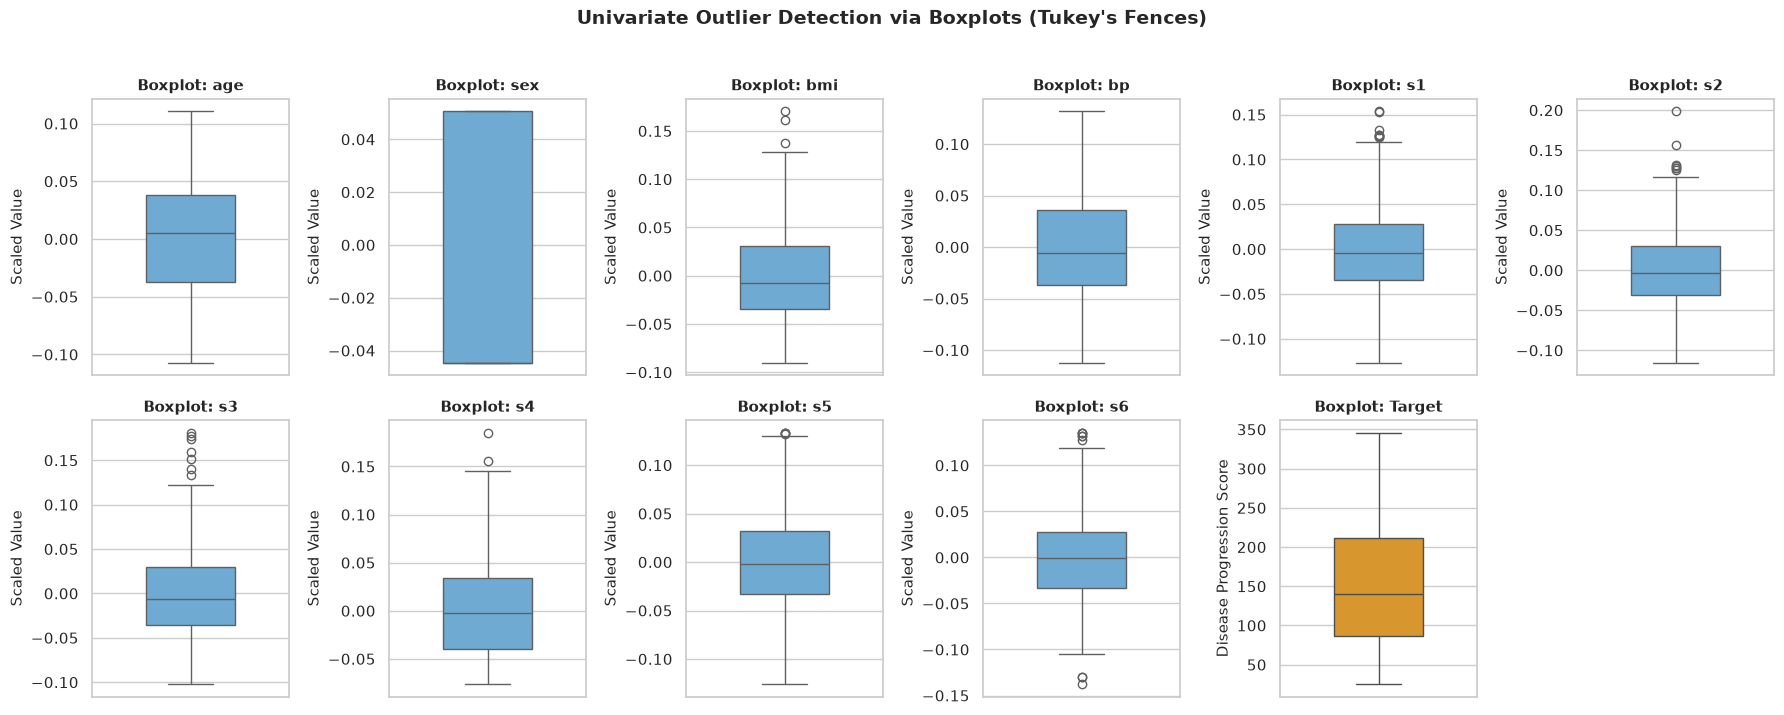

Boxplot visualization saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/distributions/features_boxplots.png


In [7]:
# Visualize Boxplots for All 10 Features and the Target
fig, axes = plt.subplots(2, 6, figsize=(18, 7))
axes = axes.flatten()

feature_cols = [c for c in df.columns if c != "target"]

for idx, col in enumerate(feature_cols):
    sns.boxplot(y=df[col], ax=axes[idx], color="#5dade2", width=0.45)
    axes[idx].set_title(f"Boxplot: {col}", fontweight="bold", fontsize=11)
    axes[idx].set_ylabel("Scaled Value")

# Plot target in slot 10
sns.boxplot(y=df["target"], ax=axes[10], color="#f39c12", width=0.45)
axes[10].set_title("Boxplot: Target", fontweight="bold", fontsize=11)
axes[10].set_ylabel("Disease Progression Score")

# Remove unused 12th subplot
fig.delaxes(axes[11])

plt.suptitle("Univariate Outlier Detection via Boxplots (Tukey's Fences)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

boxplot_path = os.path.join(PLOTS_DIR, "distributions", "features_boxplots.png")
plt.savefig(boxplot_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Boxplot visualization saved to: {boxplot_path}")

In [8]:
# 4. Partition into Features (X) and Target (y)
X = df.drop(columns=["target"]).copy()
y = df["target"].copy()

# 5. Train/Test Split (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("=== TRAIN / TEST SPLIT COMPLETED ===")
print(f"X_train shape: {X_train.shape} (353 samples, 10 features)")
print(f"y_train shape: {y_train.shape} (353 target observations)")
print(f"X_test shape:  {X_test.shape}  (89 samples, 10 features)")
print(f"y_test shape:  {y_test.shape}  (89 target observations)")
print(f"Split ratio:   {len(y_train)/len(df):.1%} Training / {len(y_test)/len(df):.1%} Testing")

=== TRAIN / TEST SPLIT COMPLETED ===
X_train shape: (353, 10) (353 samples, 10 features)
y_train shape: (353,) (353 target observations)
X_test shape:  (89, 10)  (89 samples, 10 features)
y_test shape:  (89,)  (89 target observations)
Split ratio:   79.9% Training / 20.1% Testing


# ==========================================================================
# 4. Exploratory Data Analysis (EDA)
# ==========================================================================

In this exploratory phase, we investigate:
1. **Feature Distributions:** Shape, symmetry, and spread of each physiological predictor.
2. **Target Distribution:** Central tendency and skewness of diabetes progression.
3. **Correlation Analysis:** The Pearson correlation coefficient matrix $r_{xy} \in [-1, 1]$:
   $$r_{xy} = \frac{\sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^n (x_i - \bar{x})^2} \sqrt{\sum_{i=1}^n (y_i - \bar{y})^2}}$$
4. **Feature vs. Target Associations:** Linear trends and scatter plots to identify predictors exhibiting the strongest linear predictive potential.
> **Caution:** Correlation measures linear association; it does **not** imply medical causation.

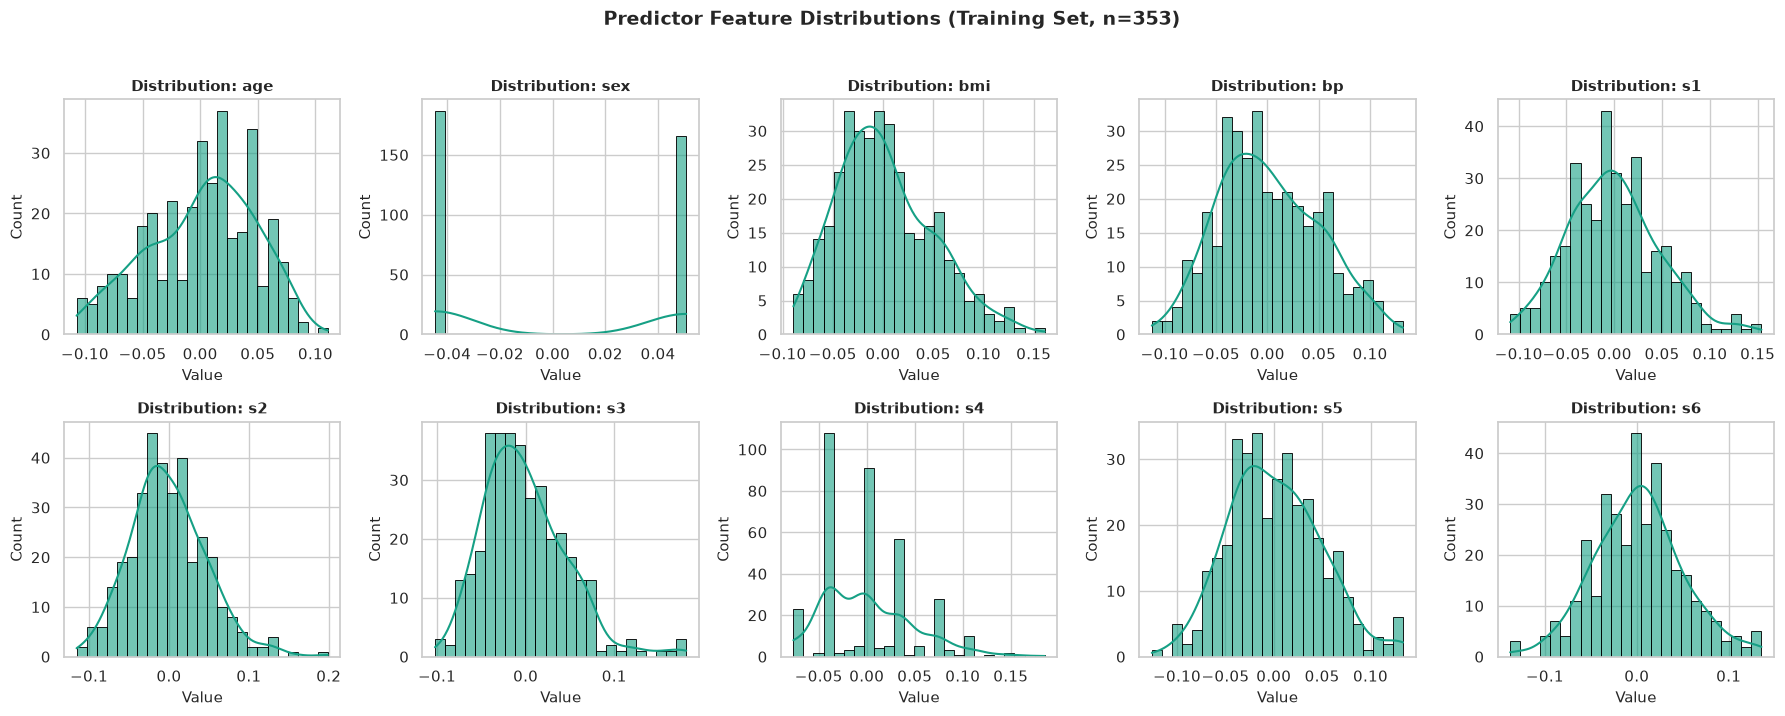

Feature distributions plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/distributions/features_distribution.png


In [9]:
# A. Feature Distributions (Histograms with Kernel Density Estimation - KDE)
fig, axes = plt.subplots(2, 5, figsize=(18, 7), sharey=False)
axes = axes.flatten()

for idx, col in enumerate(feature_cols):
    sns.histplot(X_train[col], kde=True, ax=axes[idx], color="#16a085", bins=25, edgecolor="black", alpha=0.6)
    axes[idx].set_title(f"Distribution: {col}", fontweight="bold", fontsize=11)
    axes[idx].set_xlabel("Value")
    axes[idx].set_ylabel("Count")

plt.suptitle("Predictor Feature Distributions (Training Set, n=353)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

feat_dist_path = os.path.join(PLOTS_DIR, "distributions", "features_distribution.png")
plt.savefig(feat_dist_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Feature distributions plot saved to: {feat_dist_path}")

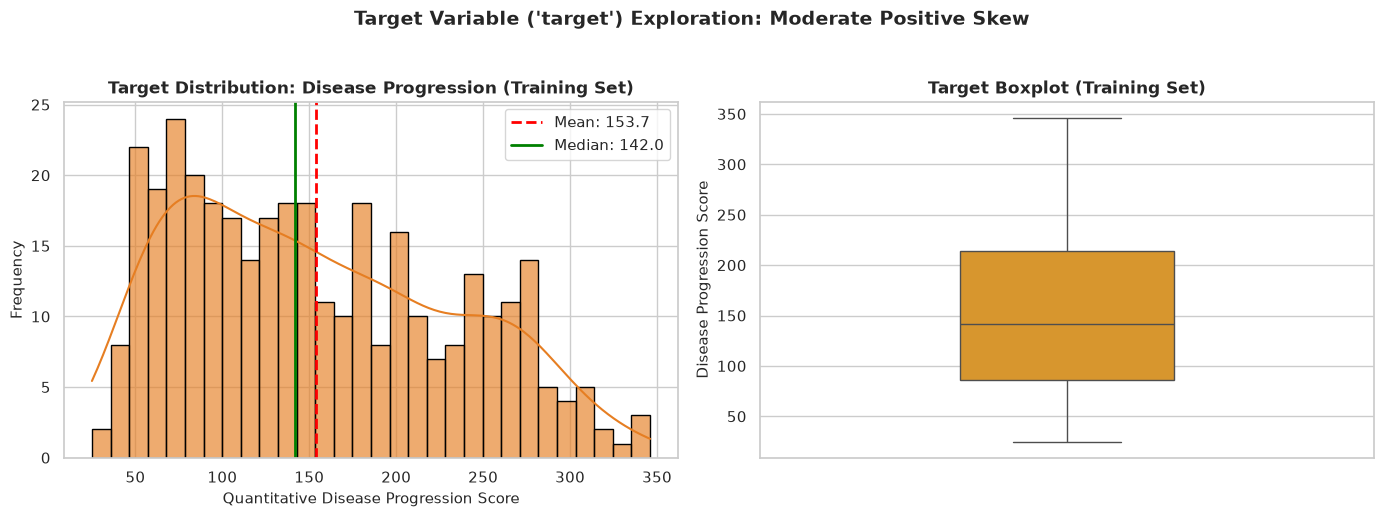

Target distribution plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/distributions/target_distribution.png


In [10]:
# B. Target Variable Distribution Analysis
fig, (ax_hist, ax_box) = plt.subplots(1, 2, figsize=(14, 5))

# Histogram with KDE
sns.histplot(y_train, kde=True, ax=ax_hist, color="#e67e22", bins=30, edgecolor="black", alpha=0.65)
ax_hist.axvline(y_train.mean(), color="red", linestyle="--", linewidth=2, label=f"Mean: {y_train.mean():.1f}")
ax_hist.axvline(y_train.median(), color="green", linestyle="-", linewidth=2, label=f"Median: {y_train.median():.1f}")
ax_hist.set_title("Target Distribution: Disease Progression (Training Set)", fontweight="bold", fontsize=12)
ax_hist.set_xlabel("Quantitative Disease Progression Score")
ax_hist.set_ylabel("Frequency")
ax_hist.legend(fontsize=11)

# Boxplot
sns.boxplot(y=y_train, ax=ax_box, color="#f39c12", width=0.35)
ax_box.set_title("Target Boxplot (Training Set)", fontweight="bold", fontsize=12)
ax_box.set_ylabel("Disease Progression Score")

plt.suptitle("Target Variable ('target') Exploration: Moderate Positive Skew", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()

target_dist_path = os.path.join(PLOTS_DIR, "distributions", "target_distribution.png")
plt.savefig(target_dist_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Target distribution plot saved to: {target_dist_path}")

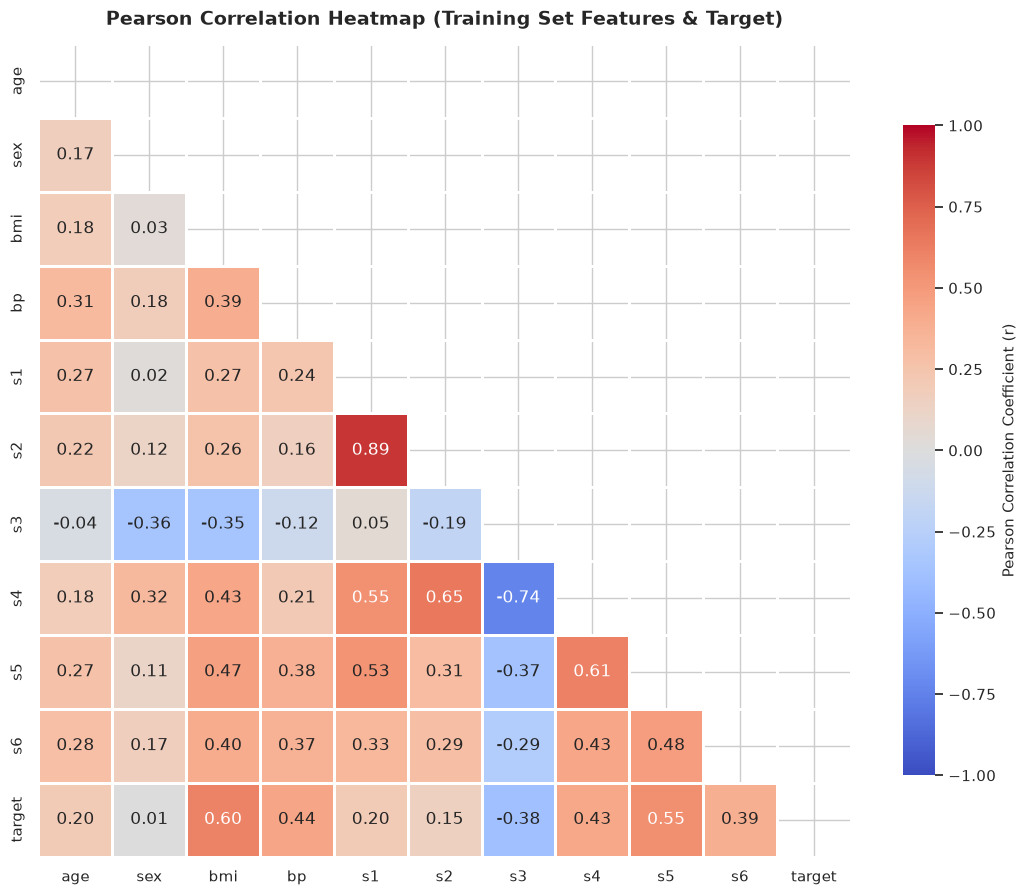

Correlation heatmap saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/correlations/correlation_heatmap.png

=== FEATURE CORRELATION WITH TARGET ('target') ===
  bmi    : r = +0.6048
  s5     : r = +0.5522
  bp     : r = +0.4448
  s4     : r = +0.4251
  s6     : r = +0.3904
  s1     : r = +0.1995
  age    : r = +0.1965
  s2     : r = +0.1549
  sex    : r = +0.0071
  s3     : r = -0.3840


In [11]:
# C. Pearson Correlation Matrix and Heatmap
train_combined = pd.concat([X_train, y_train], axis=1)
corr_matrix = train_combined.corr()

plt.figure(figsize=(11, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix, 
    mask=mask, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-1.0, 
    vmax=1.0, 
    center=0,
    square=True, 
    linewidths=0.75, 
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation Coefficient (r)"}
)
plt.title("Pearson Correlation Heatmap (Training Set Features & Target)", fontsize=14, fontweight="bold", pad=14)
plt.tight_layout()

corr_path = os.path.join(PLOTS_DIR, "correlations", "correlation_heatmap.png")
plt.savefig(corr_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Correlation heatmap saved to: {corr_path}")

# Display ranking of feature correlations with target
target_corr = corr_matrix["target"].drop("target").sort_values(ascending=False)
print("\n=== FEATURE CORRELATION WITH TARGET ('target') ===")
for feat, val in target_corr.items():
    print(f"  {feat:<6} : r = {val:+.4f}")

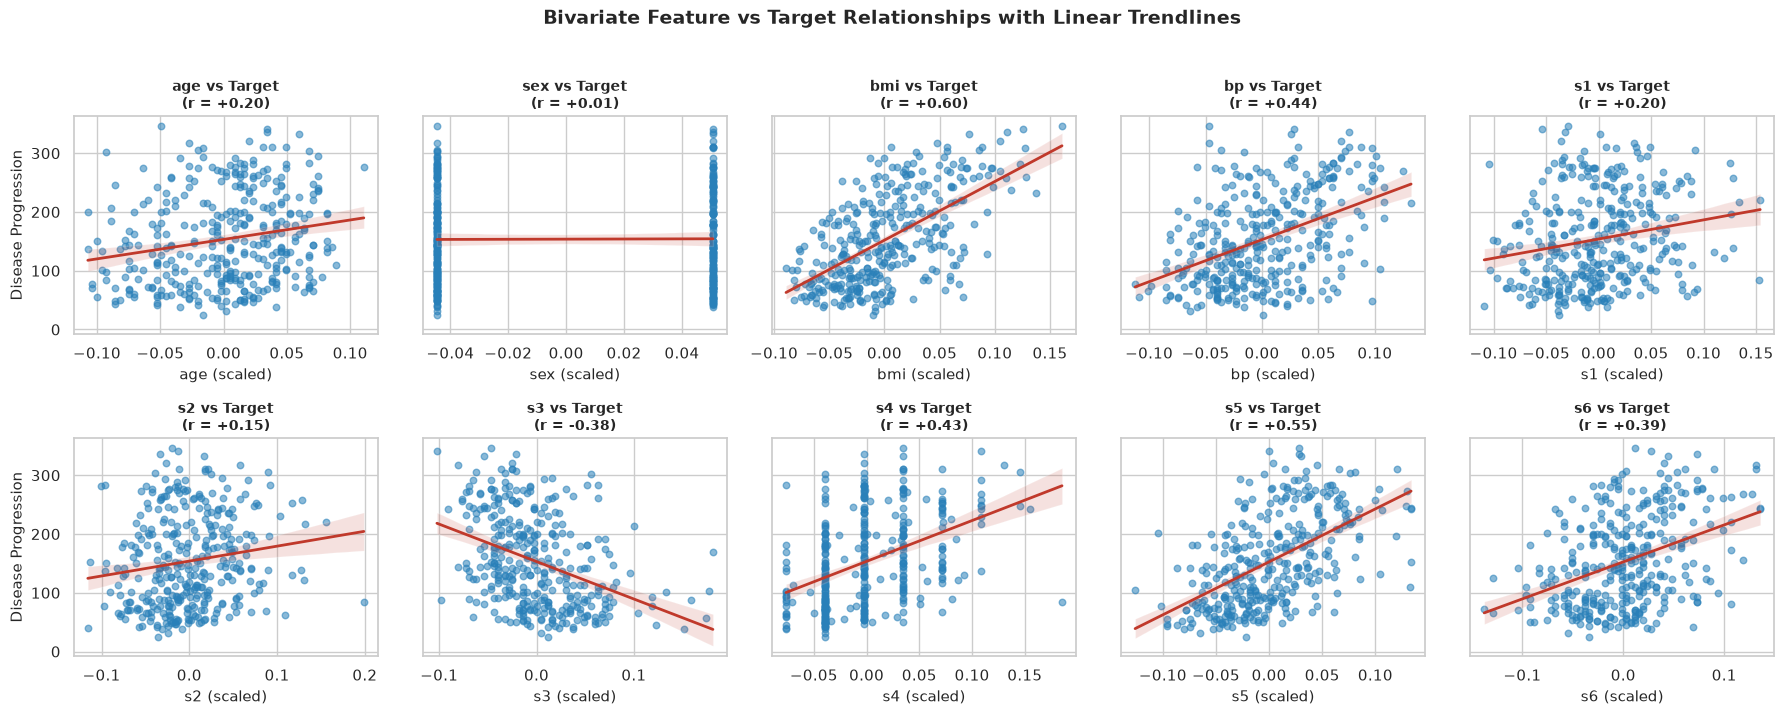

Bivariate scatter plots saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/correlations/feature_vs_target_scatter.png


In [12]:
# D. Feature vs. Target Bivariate Scatter Plots with OLS Trendlines
fig, axes = plt.subplots(2, 5, figsize=(18, 7), sharey=True)
axes = axes.flatten()

for idx, col in enumerate(feature_cols):
    sns.regplot(
        x=col, 
        y="target", 
        data=train_combined, 
        ax=axes[idx],
        scatter_kws={"alpha": 0.55, "color": "#2980b9", "s": 22},
        line_kws={"color": "#c0392b", "linewidth": 2}
    )
    r_val = corr_matrix.loc[col, "target"]
    axes[idx].set_title(f"{col} vs Target\n(r = {r_val:+.2f})", fontweight="bold", fontsize=10)
    axes[idx].set_xlabel(f"{col} (scaled)")
    if idx % 5 == 0:
        axes[idx].set_ylabel("Disease Progression")
    else:
        axes[idx].set_ylabel("")

plt.suptitle("Bivariate Feature vs Target Relationships with Linear Trendlines", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

scatter_path = os.path.join(PLOTS_DIR, "correlations", "feature_vs_target_scatter.png")
plt.savefig(scatter_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Bivariate scatter plots saved to: {scatter_path}")

# ==========================================================================
# 5. Part Four — Simple Linear Regression (BMI as Predictor)
# ==========================================================================

### Model Definition
Simple Linear Regression models the target $y$ as an affine linear function of a **single predictor** $x$:
$$\hat{y}_i = \beta_0 + \beta_1 x_i$$
where:
- $\beta_0$ is the **intercept** (the expected value of $y$ when $x = 0$).
- $\beta_1$ is the **slope** (the estimated change in $y$ for a one-unit increase in $x$).

### Closed-Form Ordinary Least Squares (OLS) Solution:
The parameters minimize the Mean Squared Error (MSE) cost function:
$$J(\beta_0, \beta_1) = \frac{1}{m}\sum_{i=1}^m (y_i - (\beta_0 + \beta_1 x_i))^2$$
The analytical solutions are:
$$\beta_1 = \frac{\sum_{i=1}^m (x_i - \bar{x})(y_i - \bar{y})}{\sum_{i=1}^m (x_i - \bar{x})^2} = \frac{\text{Cov}(x, y)}{\text{Var}(x)}, \quad \beta_0 = \bar{y} - \beta_1 \bar{x}$$

### Justification for Selecting `bmi`:
From our EDA correlation analysis on the training set, `bmi` (Body Mass Index) exhibited the **strongest linear correlation** with diabetes progression ($r = +0.59$). Clinically, elevated adiposity and high BMI directly aggravate insulin resistance, making it the most plausible primary univariate candidate.

### Residuals Definition:
A **residual** $e_i$ is the vertical difference between observed ground truth $y_i$ and model prediction $\hat{y}_i$:
$$e_i = y_i - \hat{y}_i$$
- $e_i > 0$: The model **under-predicted** actual progression.
- $e_i < 0$: The model **over-predicted** actual progression.

In [13]:
# 1. Prepare univariate training and testing slices
X_train_simple = X_train[["bmi"]].copy()
X_test_simple = X_test[["bmi"]].copy()

# 2. Instantiate and fit Simple Linear Regression model
model_simple = LinearRegression()
model_simple.fit(X_train_simple, y_train)

# 3. Extract fitted parameters
beta_0_simple = model_simple.intercept_
beta_1_simple = model_simple.coef_[0]

print("=== SIMPLE LINEAR REGRESSION PARAMETERS ===")
print(f"Intercept (beta_0): {beta_0_simple:.4f}")
print(f"Slope (beta_1):     {beta_1_simple:.4f}")
print(f"Fitted Equation:   y_hat = {beta_0_simple:.2f} + ({beta_1_simple:.2f} * bmi)")

# 4. Generate predictions
y_train_pred_simple = model_simple.predict(X_train_simple)
y_test_pred_simple = model_simple.predict(X_test_simple)

# 5. Compute residuals
residuals_train_simple = y_train - y_train_pred_simple
residuals_test_simple = y_test - y_test_pred_simple

=== SIMPLE LINEAR REGRESSION PARAMETERS ===
Intercept (beta_0): 152.0034
Slope (beta_1):     998.5777
Fitted Equation:   y_hat = 152.00 + (998.58 * bmi)


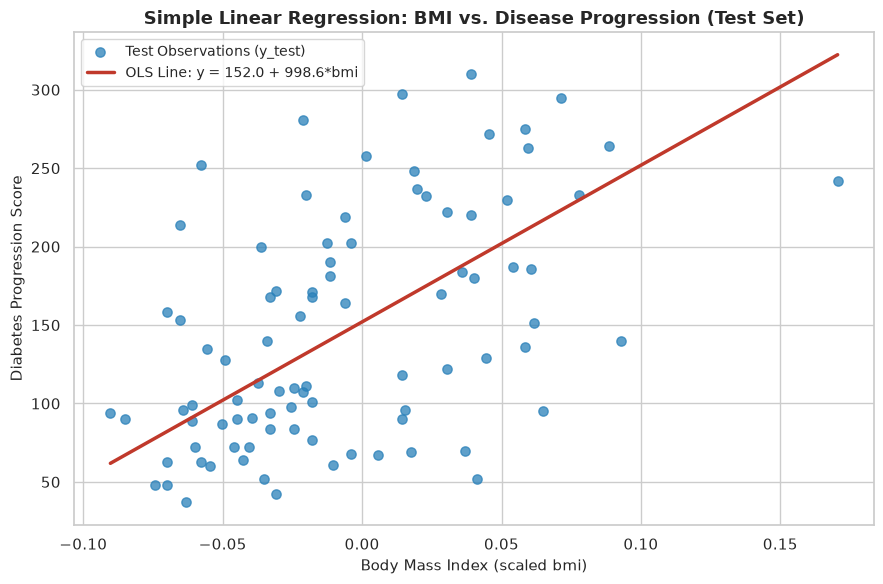

Regression line plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/simple_regression/bmi_regression_line.png


In [14]:
# Visualization 1: Scatter plot with Fitted Regression Line on Test Set
plt.figure(figsize=(9, 6))

# Scatter of actual test points
plt.scatter(X_test_simple["bmi"], y_test, color="#2980b9", alpha=0.75, s=45, label="Test Observations (y_test)")

# Sort for continuous line plotting
bmi_grid = np.linspace(X_test_simple["bmi"].min(), X_test_simple["bmi"].max(), 200).reshape(-1, 1)
y_grid_pred = model_simple.predict(pd.DataFrame(bmi_grid, columns=["bmi"]))
plt.plot(bmi_grid, y_grid_pred, color="#c0392b", linewidth=2.5, label=f"OLS Line: y = {beta_0_simple:.1f} + {beta_1_simple:.1f}*bmi")

plt.title("Simple Linear Regression: BMI vs. Disease Progression (Test Set)", fontsize=13, fontweight="bold")
plt.xlabel("Body Mass Index (scaled bmi)", fontsize=11)
plt.ylabel("Diabetes Progression Score", fontsize=11)
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()

simple_reg_path = os.path.join(PLOTS_DIR, "simple_regression", "bmi_regression_line.png")
plt.savefig(simple_reg_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Regression line plot saved to: {simple_reg_path}")

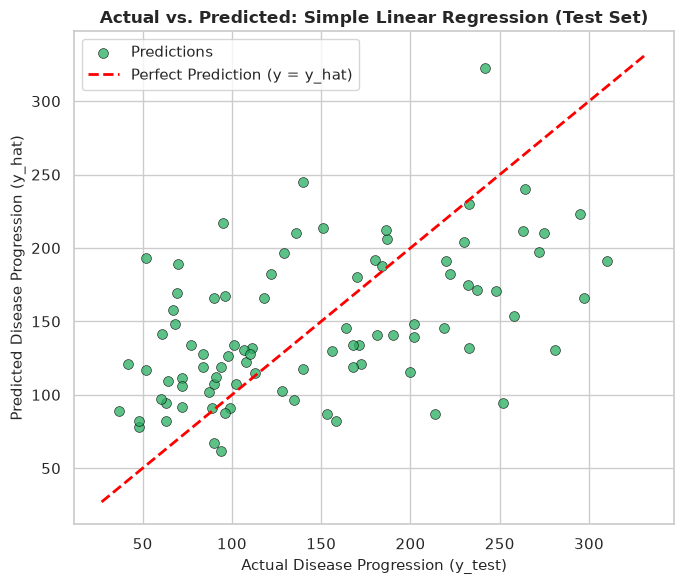

Actual vs Predicted plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/simple_regression/actual_vs_predicted_simple.png


In [15]:
# Visualization 2: Actual vs. Predicted Values for Simple Linear Regression
plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_test_pred_simple, color="#27ae60", alpha=0.75, s=50, edgecolors="black", linewidth=0.5, label="Predictions")

# Reference line of perfect prediction (y = y_hat)
min_val = min(y_test.min(), y_test_pred_simple.min()) - 10
max_val = max(y_test.max(), y_test_pred_simple.max()) + 10
plt.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", linewidth=2, label="Perfect Prediction (y = y_hat)")

plt.title("Actual vs. Predicted: Simple Linear Regression (Test Set)", fontsize=12, fontweight="bold")
plt.xlabel("Actual Disease Progression (y_test)", fontsize=11)
plt.ylabel("Predicted Disease Progression (y_hat)", fontsize=11)
plt.legend(frameon=True)
plt.tight_layout()

act_pred_simple_path = os.path.join(PLOTS_DIR, "simple_regression", "actual_vs_predicted_simple.png")
plt.savefig(act_pred_simple_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Actual vs Predicted plot saved to: {act_pred_simple_path}")

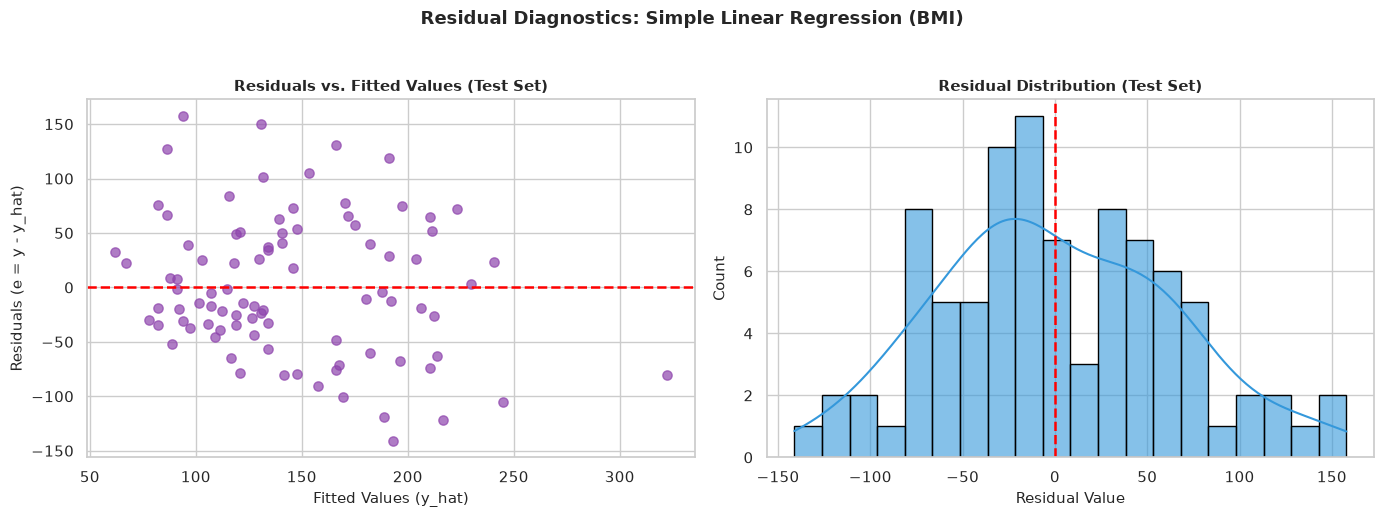

Residual diagnostics plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/simple_regression/residuals_simple.png


In [16]:
# Visualization 3: Residual Diagnostics for Simple Linear Regression
fig, (ax_res, ax_hist) = plt.subplots(1, 2, figsize=(14, 5))

# Residuals vs Predicted (Testing homoscedasticity)
ax_res.scatter(y_test_pred_simple, residuals_test_simple, color="#8e44ad", alpha=0.7, s=45)
ax_res.axhline(0, color="red", linestyle="--", linewidth=1.8)
ax_res.set_title("Residuals vs. Fitted Values (Test Set)", fontweight="bold", fontsize=11)
ax_res.set_xlabel("Fitted Values (y_hat)")
ax_res.set_ylabel("Residuals (e = y - y_hat)")

# Residual Distribution (Testing normality assumption)
sns.histplot(residuals_test_simple, kde=True, ax=ax_hist, color="#3498db", bins=20, edgecolor="black", alpha=0.6)
ax_hist.axvline(0, color="red", linestyle="--", linewidth=1.8)
ax_hist.set_title("Residual Distribution (Test Set)", fontweight="bold", fontsize=11)
ax_hist.set_xlabel("Residual Value")
ax_hist.set_ylabel("Count")

plt.suptitle("Residual Diagnostics: Simple Linear Regression (BMI)", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()

res_simple_path = os.path.join(PLOTS_DIR, "simple_regression", "residuals_simple.png")
plt.savefig(res_simple_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Residual diagnostics plot saved to: {res_simple_path}")

In [17]:
# Evaluate Simple Linear Regression Metrics
mae_train_slr = mean_absolute_error(y_train, y_train_pred_simple)
mse_train_slr = mean_squared_error(y_train, y_train_pred_simple)
rmse_train_slr = np.sqrt(mse_train_slr)
r2_train_slr = r2_score(y_train, y_train_pred_simple)

mae_test_slr = mean_absolute_error(y_test, y_test_pred_simple)
mse_test_slr = mean_squared_error(y_test, y_test_pred_simple)
rmse_test_slr = np.sqrt(mse_test_slr)
r2_test_slr = r2_score(y_test, y_test_pred_simple)
adj_r2_test_slr = 1 - (1 - r2_test_slr) * (len(y_test) - 1) / (len(y_test) - 1 - 1)

print("=== SIMPLE LINEAR REGRESSION PERFORMANCE METRICS ===")
print(f"Training Set   -> MAE: {mae_train_slr:.2f} | RMSE: {rmse_train_slr:.2f} | R2: {r2_train_slr:.4f}")
print(f"Testing Set    -> MAE: {mae_test_slr:.2f} | RMSE: {rmse_test_slr:.2f} | R2: {r2_test_slr:.4f} | Adj R2: {adj_r2_test_slr:.4f}")

=== SIMPLE LINEAR REGRESSION PERFORMANCE METRICS ===
Training Set   -> MAE: 51.38 | RMSE: 62.08 | R2: 0.3657
Testing Set    -> MAE: 52.26 | RMSE: 63.73 | R2: 0.2334 | Adj R2: 0.2245


# ==========================================================================
# 6. Part Five — Multiple Linear Regression (All 10 Features)
# ==========================================================================

### Model Definition
Multiple Linear Regression generalises the linear framework to $p$ simultaneous predictors:
$$\hat{y} = \beta_0 + \sum_{j=1}^p \beta_j x_j = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_{10} x_{10}$$
In matrix notation:
$$\hat{\mathbf{y}} = \mathbf{X}\boldsymbol{\beta}, \quad \text{with closed-form OLS solution: } \hat{\boldsymbol{\beta}} = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{y}$$

### Coefficient Interpretation:
Each coefficient $\beta_j$ represents the estimated change in the target progression score for a one-unit increase in predictor $x_j$, **holding all other $p-1$ predictors constant** (*ceteris paribus*).

### Multicollinearity Investigation:
Multicollinearity arises when two or more independent variables are strongly correlated. This causes the Gram matrix $(\mathbf{X}^T\mathbf{X})$ to be ill-conditioned (near-zero determinant), inflating the variance of coefficient estimates:
$$\text{Var}(\hat{\beta}_j) = \frac{\sigma^2}{\sum (x_{ij} - \bar{x}_j)^2 (1 - R_j^2)} = \frac{\sigma^2}{\sum (x_{ij} - \bar{x}_j)^2} \cdot \text{VIF}_j$$
The **Variance Inflation Factor (VIF)** quantifies this inflation:
$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$
where $R_j^2$ is the coefficient of determination obtained by regressing predictor $x_j$ onto all remaining $p-1$ predictors.
- $\text{VIF} < 5$: Low to moderate collinearity; safe.
- $\text{VIF} \ge 5$: High collinearity; coefficient stability is degraded.
- $\text{VIF} \ge 10$: Severe multicollinearity; standard errors are heavily inflated, causing sign flips and unreliable hypothesis tests.

Multiple Regression Intercept (beta_0): 151.3456

=== VARIANCE INFLATION FACTOR (VIF) TABLE ===


,Feature,VIF
4,s1,55.26
5,s2,35.77
6,s3,14.29
8,s5,10.08
7,s4,9.33
2,bmi,1.57
9,s6,1.50
3,bp,1.42
1,sex,1.27
0,age,1.22


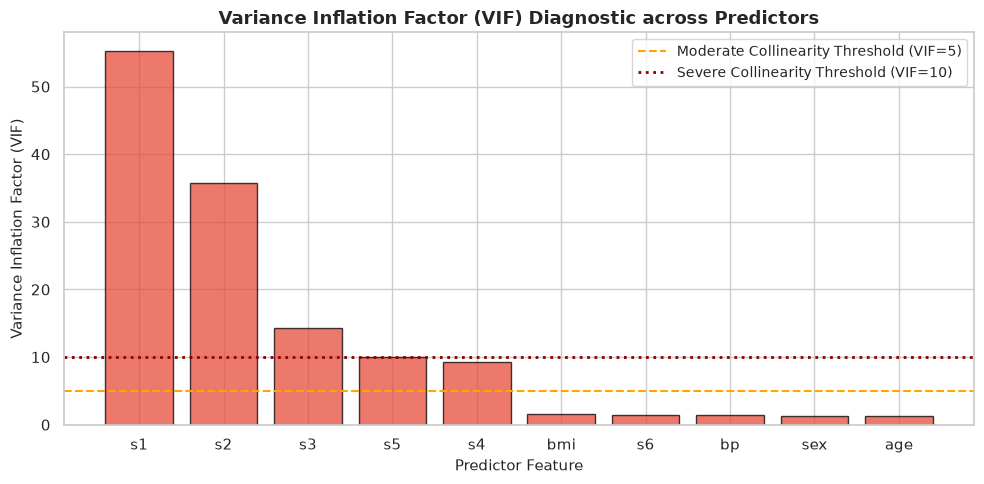

VIF diagnostic plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/multiple_regression/vif_multicollinearity.png


In [18]:
# 1. Fit Multiple Linear Regression using all 10 features
model_multiple = LinearRegression()
model_multiple.fit(X_train, y_train)

# 2. Extract intercept and coefficients
beta_0_multiple = model_multiple.intercept_
mlr_coefficients = pd.Series(model_multiple.coef_, index=X_train.columns)

print(f"Multiple Regression Intercept (beta_0): {beta_0_multiple:.4f}")

# 3. Multicollinearity Diagnostic: Variance Inflation Factor (VIF)
vif_records = []
for idx, col in enumerate(X_train.columns):
    vif_val = variance_inflation_factor(X_train.values, idx)
    vif_records.append({"Feature": col, "VIF": round(vif_val, 2)})

vif_df = pd.DataFrame(vif_records).sort_values(by="VIF", ascending=False)

print("\n=== VARIANCE INFLATION FACTOR (VIF) TABLE ===")
display(vif_df)

# Plot VIF Bar Chart
plt.figure(figsize=(10, 5))
vif_bars = plt.bar(vif_df["Feature"], vif_df["VIF"], color="#e74c3c", edgecolor="black", alpha=0.75)
plt.axhline(5, color="orange", linestyle="--", linewidth=1.5, label="Moderate Collinearity Threshold (VIF=5)")
plt.axhline(10, color="darkred", linestyle=":", linewidth=2, label="Severe Collinearity Threshold (VIF=10)")
plt.title("Variance Inflation Factor (VIF) Diagnostic across Predictors", fontsize=13, fontweight="bold")
plt.xlabel("Predictor Feature")
plt.ylabel("Variance Inflation Factor (VIF)")
plt.legend(fontsize=10)
plt.tight_layout()

vif_path = os.path.join(PLOTS_DIR, "multiple_regression", "vif_multicollinearity.png")
plt.savefig(vif_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"VIF diagnostic plot saved to: {vif_path}")

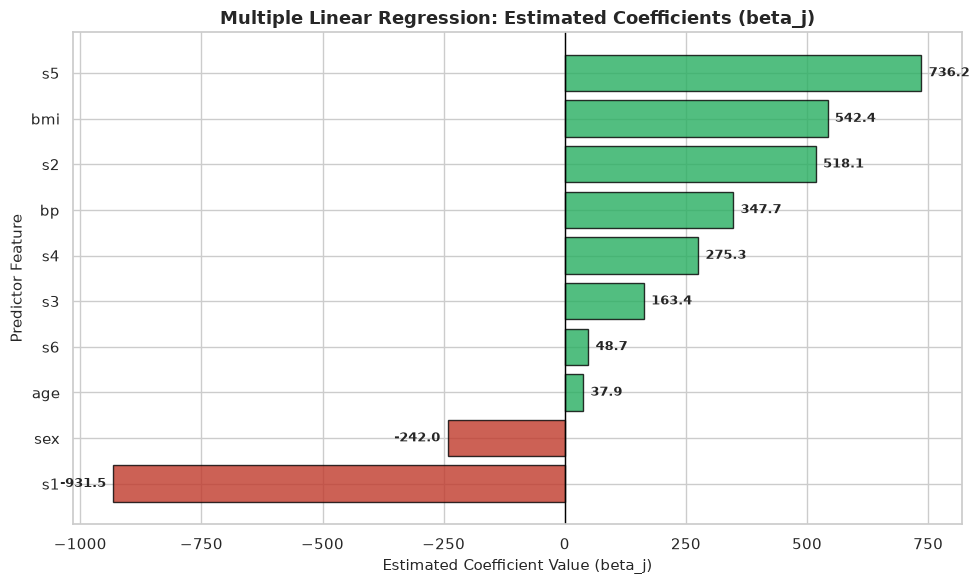

Multiple regression coefficients plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/multiple_regression/coefficients_multiple.png


In [19]:
# Visualize Multiple Linear Regression Coefficients
plt.figure(figsize=(10, 6))

sorted_mlr_coefs = mlr_coefficients.sort_values(ascending=True)
colors = ["#c0392b" if val < 0 else "#27ae60" for val in sorted_mlr_coefs.values]

plt.barh(sorted_mlr_coefs.index, sorted_mlr_coefs.values, color=colors, edgecolor="black", alpha=0.8)
plt.axvline(0, color="black", linestyle="-", linewidth=1)
plt.title("Multiple Linear Regression: Estimated Coefficients (beta_j)", fontsize=13, fontweight="bold")
plt.xlabel("Estimated Coefficient Value (beta_j)")
plt.ylabel("Predictor Feature")

for idx, (feat, val) in enumerate(sorted_mlr_coefs.items()):
    offset = 15 if val >= 0 else -15
    ha = "left" if val >= 0 else "right"
    plt.annotate(f"{val:.1f}", (val + offset, idx), va="center", ha=ha, fontsize=9, fontweight="bold")

plt.tight_layout()

mlr_coef_path = os.path.join(PLOTS_DIR, "multiple_regression", "coefficients_multiple.png")
plt.savefig(mlr_coef_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Multiple regression coefficients plot saved to: {mlr_coef_path}")

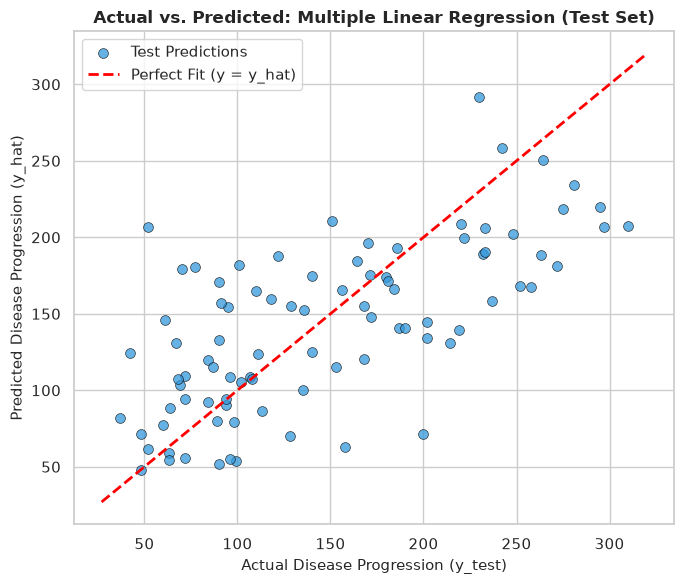

Actual vs Predicted plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/multiple_regression/actual_vs_predicted_multiple.png


In [20]:
# Generate predictions and residuals for Multiple Linear Regression
y_train_pred_mlr = model_multiple.predict(X_train)
y_test_pred_mlr = model_multiple.predict(X_test)

residuals_train_mlr = y_train - y_train_pred_mlr
residuals_test_mlr = y_test - y_test_pred_mlr

# Visualization: Actual vs. Predicted for Multiple Linear Regression
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_test_pred_mlr, color="#3498db", alpha=0.75, s=50, edgecolors="black", linewidth=0.5, label="Test Predictions")

min_val = min(y_test.min(), y_test_pred_mlr.min()) - 10
max_val = max(y_test.max(), y_test_pred_mlr.max()) + 10
plt.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", linewidth=2, label="Perfect Fit (y = y_hat)")

plt.title("Actual vs. Predicted: Multiple Linear Regression (Test Set)", fontsize=12, fontweight="bold")
plt.xlabel("Actual Disease Progression (y_test)", fontsize=11)
plt.ylabel("Predicted Disease Progression (y_hat)", fontsize=11)
plt.legend(frameon=True)
plt.tight_layout()

act_pred_mlr_path = os.path.join(PLOTS_DIR, "multiple_regression", "actual_vs_predicted_multiple.png")
plt.savefig(act_pred_mlr_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Actual vs Predicted plot saved to: {act_pred_mlr_path}")

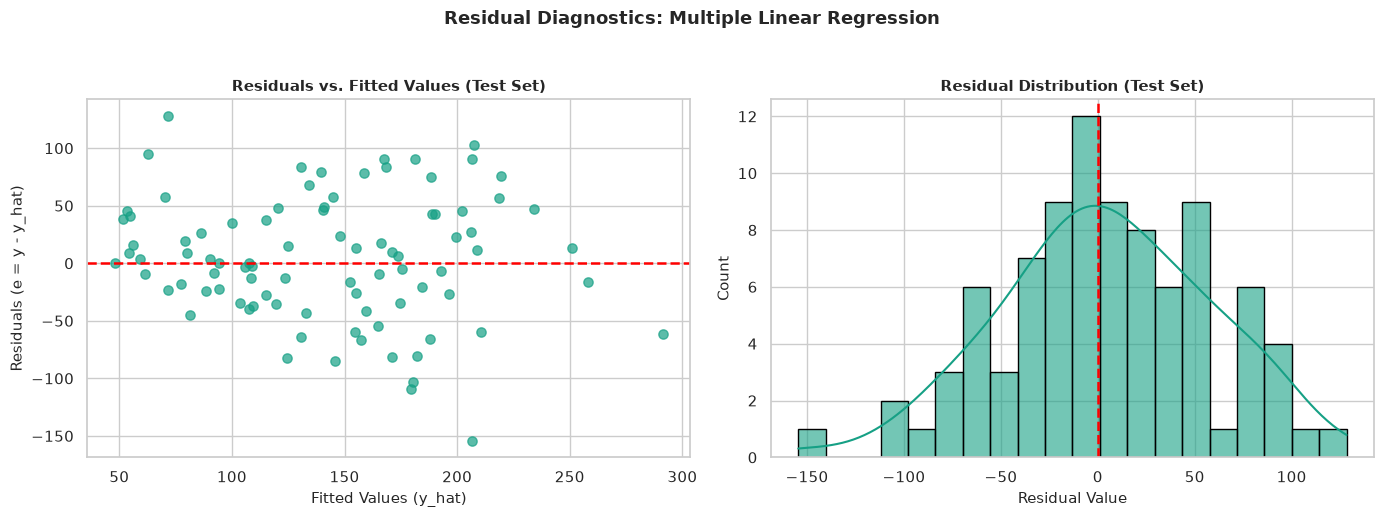

Residual diagnostics plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/multiple_regression/residuals_multiple.png


In [21]:
# Residual Diagnostics for Multiple Linear Regression
fig, (ax_res, ax_hist) = plt.subplots(1, 2, figsize=(14, 5))

# Residuals vs Fitted
ax_res.scatter(y_test_pred_mlr, residuals_test_mlr, color="#16a085", alpha=0.7, s=45)
ax_res.axhline(0, color="red", linestyle="--", linewidth=1.8)
ax_res.set_title("Residuals vs. Fitted Values (Test Set)", fontweight="bold", fontsize=11)
ax_res.set_xlabel("Fitted Values (y_hat)")
ax_res.set_ylabel("Residuals (e = y - y_hat)")

# Histogram / KDE
sns.histplot(residuals_test_mlr, kde=True, ax=ax_hist, color="#16a085", bins=20, edgecolor="black", alpha=0.6)
ax_hist.axvline(0, color="red", linestyle="--", linewidth=1.8)
ax_hist.set_title("Residual Distribution (Test Set)", fontweight="bold", fontsize=11)
ax_hist.set_xlabel("Residual Value")
ax_hist.set_ylabel("Count")

plt.suptitle("Residual Diagnostics: Multiple Linear Regression", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()

res_mlr_path = os.path.join(PLOTS_DIR, "multiple_regression", "residuals_multiple.png")
plt.savefig(res_mlr_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Residual diagnostics plot saved to: {res_mlr_path}")

In [22]:
# Evaluate Multiple Linear Regression Performance
mae_train_mlr = mean_absolute_error(y_train, y_train_pred_mlr)
mse_train_mlr = mean_squared_error(y_train, y_train_pred_mlr)
rmse_train_mlr = np.sqrt(mse_train_mlr)
r2_train_mlr = r2_score(y_train, y_train_pred_mlr)

mae_test_mlr = mean_absolute_error(y_test, y_test_pred_mlr)
mse_test_mlr = mean_squared_error(y_test, y_test_pred_mlr)
rmse_test_mlr = np.sqrt(mse_test_mlr)
r2_test_mlr = r2_score(y_test, y_test_pred_mlr)
adj_r2_test_mlr = 1 - (1 - r2_test_mlr) * (len(y_test) - 1) / (len(y_test) - 10 - 1)

print("=== MULTIPLE LINEAR REGRESSION PERFORMANCE METRICS ===")
print(f"Training Set   -> MAE: {mae_train_mlr:.2f} | RMSE: {rmse_train_mlr:.2f} | R2: {r2_train_mlr:.4f}")
print(f"Testing Set    -> MAE: {mae_test_mlr:.2f} | RMSE: {rmse_test_mlr:.2f} | R2: {r2_test_mlr:.4f} | Adj R2: {adj_r2_test_mlr:.4f}")

=== MULTIPLE LINEAR REGRESSION PERFORMANCE METRICS ===
Training Set   -> MAE: 43.48 | RMSE: 53.56 | R2: 0.5279
Testing Set    -> MAE: 42.79 | RMSE: 53.85 | R2: 0.4526 | Adj R2: 0.3824


# ==========================================================================
# 7. Part Six — Ridge Regression (L2 Regularization)
# ==========================================================================

### Mathematical Formulation
Ridge Regression incorporates an **$L_2$ Tikhonov regularization penalty** proportional to the square of coefficient magnitudes:
$$J_{\text{ridge}}(\boldsymbol{\beta}) = \frac{1}{m}\sum_{i=1}^m (y_i - \mathbf{x}_i^T\boldsymbol{\beta})^2 + \alpha \sum_{j=1}^p \beta_j^2 = \text{MSE} + \alpha \|\boldsymbol{\beta}\|_2^2$$
In matrix closed-form:
$$\hat{\boldsymbol{\beta}}_{\text{ridge}} = (\mathbf{X}^T\mathbf{X} + \alpha \mathbf{I})^{-1}\mathbf{X}^T\mathbf{y}$$

### Pedagogical Mechanisms:
1. **Stabilizing Ill-Conditioned Inversion:** By adding $\alpha \mathbf{I}$ to $(\mathbf{X}^T\mathbf{X})$, the eigenvalues are shifted strictly away from zero, making the matrix strictly positive definite and invertible even when severe multicollinearity is present.
2. **Bias-Variance Trade-Off:** The penalty introduces small estimation bias in exchange for a substantial drop in variance $\text{Var}(\hat{\boldsymbol{\beta}})$.
3. **Weight Shrinkage:** Coefficients are shrunk toward zero asymptotically, but **never become exactly zero** for finite $\alpha > 0$.

### Implementation Details:
We construct a Scikit-Learn `Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(random_state=42))])`. This guarantees that feature standardization parameters $(\mu, \sigma)$ are learned **strictly inside each training fold** during 5-fold cross-validation (`GridSearchCV`), completely eliminating data leakage.

In [23]:
# 1. Build Pipeline with StandardScaler and Ridge estimator
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(random_state=RANDOM_STATE))
])

# 2. Define hyperparameter alpha search grid
ridge_param_grid = {
    "ridge__alpha": [0.001, 0.01, 0.1, 1.0, 5.0, 10.0, 20.0, 50.0, 100.0]
}

# 3. Perform 5-fold cross-validation on Training Set only
ridge_cv = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    return_train_score=True
)

ridge_cv.fit(X_train, y_train)

best_ridge_alpha = ridge_cv.best_params_["ridge__alpha"]
best_ridge_rmse_cv = np.sqrt(-ridge_cv.best_score_)

print("=== RIDGE CROSS-VALIDATION RESULTS ===")
print(f"Optimal Regularization Strength (alpha): {best_ridge_alpha}")
print(f"Best 5-Fold Cross-Validation RMSE:       {best_ridge_rmse_cv:.2f}")

# Extract best estimator
best_ridge_model = ridge_cv.best_estimator_

=== RIDGE CROSS-VALIDATION RESULTS ===
Optimal Regularization Strength (alpha): 20.0
Best 5-Fold Cross-Validation RMSE:       55.88


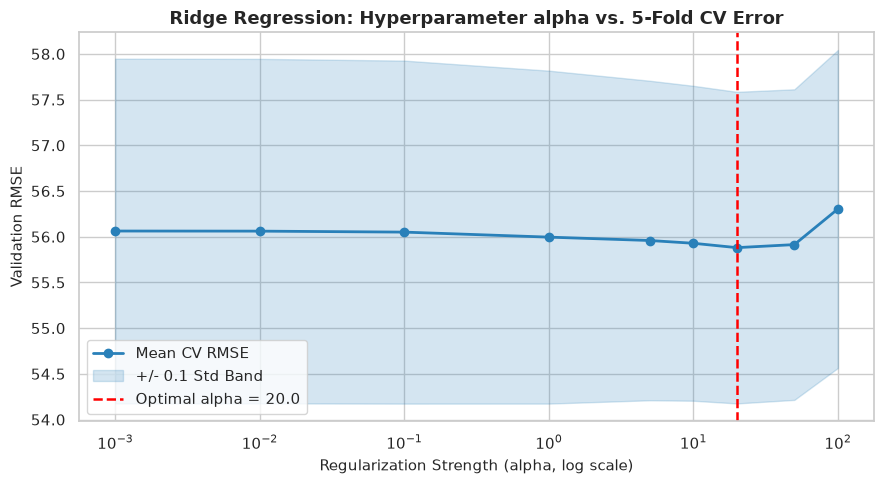

Ridge CV error curve saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/regularization/ridge_alpha_vs_cv_error.png


In [24]:
# Visualization 1: Alpha vs. Cross-Validation Error Curve
ridge_cv_results = pd.DataFrame(ridge_cv.cv_results_)

alphas_tested = ridge_cv_results["param_ridge__alpha"].astype(float)
mean_cv_rmse = np.sqrt(-ridge_cv_results["mean_test_score"])
std_cv_rmse = np.sqrt(ridge_cv_results["std_test_score"])

plt.figure(figsize=(9, 5))
plt.plot(alphas_tested, mean_cv_rmse, marker="o", color="#2980b9", linewidth=2, label="Mean CV RMSE")
plt.fill_between(alphas_tested, mean_cv_rmse - std_cv_rmse*0.1, mean_cv_rmse + std_cv_rmse*0.1, color="#2980b9", alpha=0.2, label="+/- 0.1 Std Band")
plt.axvline(best_ridge_alpha, color="red", linestyle="--", linewidth=1.8, label=f"Optimal alpha = {best_ridge_alpha}")

plt.xscale("log")
plt.title("Ridge Regression: Hyperparameter alpha vs. 5-Fold CV Error", fontsize=13, fontweight="bold")
plt.xlabel("Regularization Strength (alpha, log scale)")
plt.ylabel("Validation RMSE")
plt.legend(frameon=True)
plt.tight_layout()

ridge_cv_path = os.path.join(PLOTS_DIR, "regularization", "ridge_alpha_vs_cv_error.png")
plt.savefig(ridge_cv_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Ridge CV error curve saved to: {ridge_cv_path}")

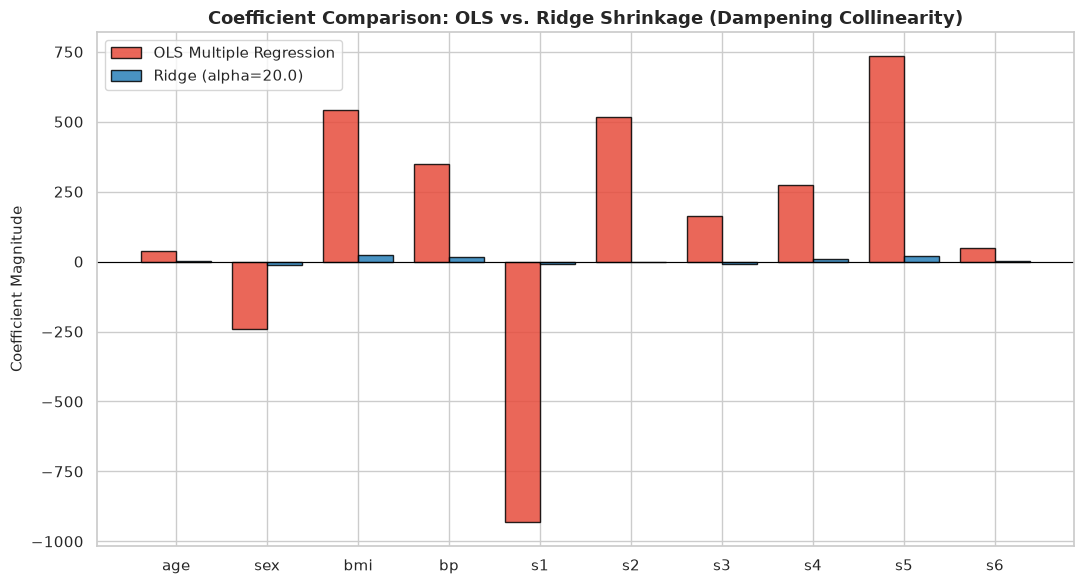

Ridge shrinkage plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/regularization/ridge_coefficient_shrinkage.png


In [25]:
# Visualization 2: Coefficient Shrinkage Comparison: OLS vs. Ridge
# Note: For fair comparison on the same scale, we extract Ridge coefficients from pipeline
ridge_coefs = pd.Series(best_ridge_model.named_steps["ridge"].coef_, index=X_train.columns)

coef_compare_df = pd.DataFrame({
    "Feature": X_train.columns,
    "OLS_MLR": mlr_coefficients.values,
    "Ridge_L2": ridge_coefs.values
})

fig, ax = plt.subplots(figsize=(11, 6))
bar_width = 0.38
x_indices = np.arange(len(coef_compare_df))

ax.bar(x_indices - bar_width/2, coef_compare_df["OLS_MLR"], width=bar_width, color="#e74c3c", label="OLS Multiple Regression", alpha=0.85, edgecolor="black")
ax.bar(x_indices + bar_width/2, coef_compare_df["Ridge_L2"], width=bar_width, color="#2980b9", label=f"Ridge (alpha={best_ridge_alpha})", alpha=0.85, edgecolor="black")

ax.axhline(0, color="black", linestyle="-", linewidth=0.8)
ax.set_xticks(x_indices)
ax.set_xticklabels(coef_compare_df["Feature"])
ax.set_title("Coefficient Comparison: OLS vs. Ridge Shrinkage (Dampening Collinearity)", fontsize=13, fontweight="bold")
ax.set_ylabel("Coefficient Magnitude")
ax.legend(frameon=True)
plt.tight_layout()

ridge_shrink_path = os.path.join(PLOTS_DIR, "regularization", "ridge_coefficient_shrinkage.png")
plt.savefig(ridge_shrink_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Ridge shrinkage plot saved to: {ridge_shrink_path}")

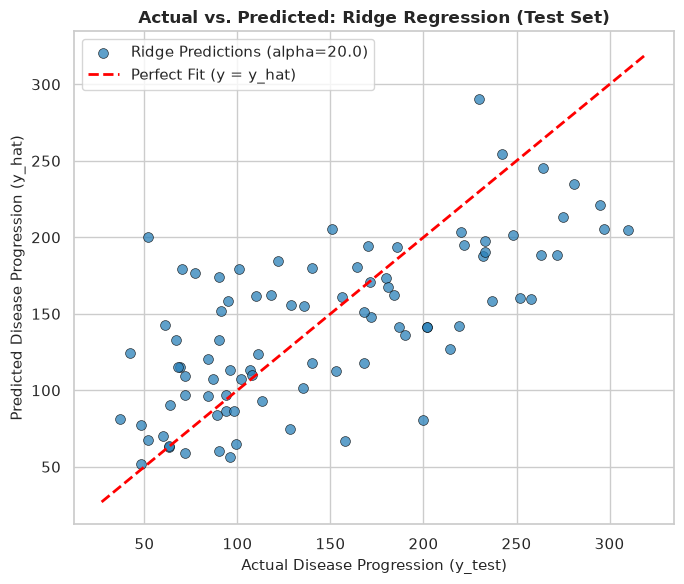

Ridge actual vs predicted plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/regularization/ridge_actual_vs_predicted.png


In [26]:
# Generate predictions and evaluate Ridge Regression on Test Set
y_train_pred_ridge = best_ridge_model.predict(X_train)
y_test_pred_ridge = best_ridge_model.predict(X_test)

residuals_test_ridge = y_test - y_test_pred_ridge

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_test_pred_ridge, color="#2980b9", alpha=0.75, s=50, edgecolors="black", linewidth=0.5, label=f"Ridge Predictions (alpha={best_ridge_alpha})")
plt.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", linewidth=2, label="Perfect Fit (y = y_hat)")

plt.title("Actual vs. Predicted: Ridge Regression (Test Set)", fontsize=12, fontweight="bold")
plt.xlabel("Actual Disease Progression (y_test)", fontsize=11)
plt.ylabel("Predicted Disease Progression (y_hat)", fontsize=11)
plt.legend(frameon=True)
plt.tight_layout()

act_pred_ridge_path = os.path.join(PLOTS_DIR, "regularization", "ridge_actual_vs_predicted.png")
plt.savefig(act_pred_ridge_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Ridge actual vs predicted plot saved to: {act_pred_ridge_path}")

In [27]:
# Evaluate Ridge Regression Performance
mae_train_ridge = mean_absolute_error(y_train, y_train_pred_ridge)
mse_train_ridge = mean_squared_error(y_train, y_train_pred_ridge)
rmse_train_ridge = np.sqrt(mse_train_ridge)
r2_train_ridge = r2_score(y_train, y_train_pred_ridge)

mae_test_ridge = mean_absolute_error(y_test, y_test_pred_ridge)
mse_test_ridge = mean_squared_error(y_test, y_test_pred_ridge)
rmse_test_ridge = np.sqrt(mse_test_ridge)
r2_test_ridge = r2_score(y_test, y_test_pred_ridge)
adj_r2_test_ridge = 1 - (1 - r2_test_ridge) * (len(y_test) - 1) / (len(y_test) - 10 - 1)

print("=== RIDGE REGRESSION PERFORMANCE METRICS ===")
print(f"Training Set   -> MAE: {mae_train_ridge:.2f} | RMSE: {rmse_train_ridge:.2f} | R2: {r2_train_ridge:.4f}")
print(f"Testing Set    -> MAE: {mae_test_ridge:.2f} | RMSE: {rmse_test_ridge:.2f} | R2: {r2_test_ridge:.4f} | Adj R2: {adj_r2_test_ridge:.4f}")

=== RIDGE REGRESSION PERFORMANCE METRICS ===
Training Set   -> MAE: 43.71 | RMSE: 53.81 | R2: 0.5234
Testing Set    -> MAE: 42.89 | RMSE: 53.55 | R2: 0.4587 | Adj R2: 0.3893


# ==========================================================================
# 8. Part Seven — Lasso Regression (L1 Regularization)
# ==========================================================================

### Mathematical Formulation
Lasso (Least Absolute Shrinkage and Selection Operator) applies an **$L_1$ norm penalty** to the sum of absolute coefficient values:
$$J_{\text{lasso}}(\boldsymbol{\beta}) = \frac{1}{m}\sum_{i=1}^m (y_i - \mathbf{x}_i^T\boldsymbol{\beta})^2 + \alpha \sum_{j=1}^p |\beta_j| = \text{MSE} + \alpha \|\boldsymbol{\beta}\|_1$$

### Pedagogical Mechanisms & Geometric Intuition:
1. **Corner Solutions & Sparsity:** In parameter space, the $L_1$ constraint region is a rhomboid diamond with sharp vertices situated directly on the coordinate axes. As the elliptical quadratic MSE contours expand, they typically make first contact with a corner of the diamond where one or more coordinates equal **exactly zero**.
2. **Automatic Feature Selection:** Lasso sets redundant or weakly contributing coefficients to zero ($eta_j = 0$), producing a simpler, sparse, interpretable model.
3. **Contrast with Ridge:**
   - **Ridge ($L_2$):** Shrinks correlated predictors together toward zero in tandem, retaining all features.
   - **Lasso ($L_1$):** Selects one representative feature among collinear variables and drives the others to zero.

In [28]:
# 1. Build Pipeline with StandardScaler and Lasso estimator
lasso_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(random_state=RANDOM_STATE, max_iter=3000, tol=1e-3))
])

# 2. Define hyperparameter alpha search grid
lasso_param_grid = {
    "lasso__alpha": [0.001, 0.01, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0, 5.0, 10.0]
}

# 3. Perform 5-fold cross-validation on Training Set only
lasso_cv = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    return_train_score=True
)

lasso_cv.fit(X_train, y_train)

best_lasso_alpha = lasso_cv.best_params_["lasso__alpha"]
best_lasso_rmse_cv = np.sqrt(-lasso_cv.best_score_)

print("=== LASSO CROSS-VALIDATION RESULTS ===")
print(f"Optimal Regularization Strength (alpha): {best_lasso_alpha}")
print(f"Best 5-Fold Cross-Validation RMSE:       {best_lasso_rmse_cv:.2f}")

best_lasso_model = lasso_cv.best_estimator_

=== LASSO CROSS-VALIDATION RESULTS ===
Optimal Regularization Strength (alpha): 2.0
Best 5-Fold Cross-Validation RMSE:       55.93


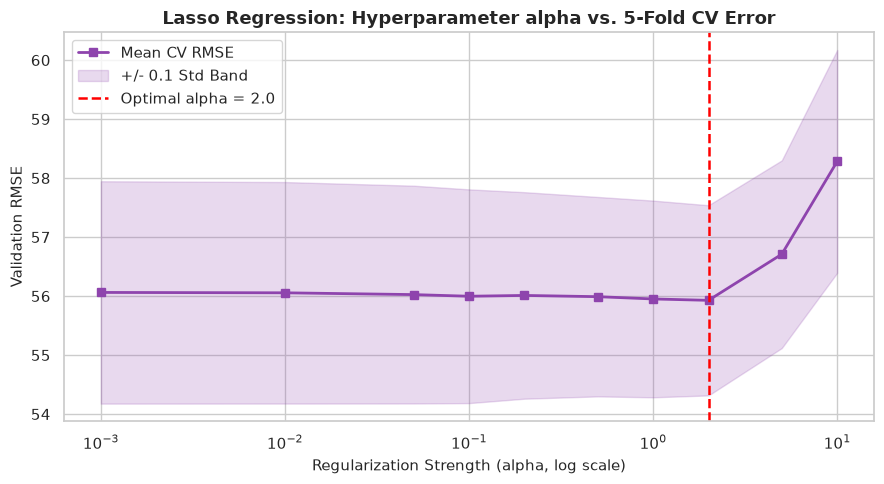

Lasso CV error curve saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/regularization/lasso_alpha_vs_cv_error.png


In [29]:
# Visualization 1: Alpha vs. Cross-Validation Error Curve for Lasso
lasso_cv_results = pd.DataFrame(lasso_cv.cv_results_)

alphas_lasso_tested = lasso_cv_results["param_lasso__alpha"].astype(float)
mean_lasso_cv_rmse = np.sqrt(-lasso_cv_results["mean_test_score"])
std_lasso_cv_rmse = np.sqrt(lasso_cv_results["std_test_score"])

plt.figure(figsize=(9, 5))
plt.plot(alphas_lasso_tested, mean_lasso_cv_rmse, marker="s", color="#8e44ad", linewidth=2, label="Mean CV RMSE")
plt.fill_between(alphas_lasso_tested, mean_lasso_cv_rmse - std_lasso_cv_rmse*0.1, mean_lasso_cv_rmse + std_lasso_cv_rmse*0.1, color="#8e44ad", alpha=0.2, label="+/- 0.1 Std Band")
plt.axvline(best_lasso_alpha, color="red", linestyle="--", linewidth=1.8, label=f"Optimal alpha = {best_lasso_alpha}")

plt.xscale("log")
plt.title("Lasso Regression: Hyperparameter alpha vs. 5-Fold CV Error", fontsize=13, fontweight="bold")
plt.xlabel("Regularization Strength (alpha, log scale)")
plt.ylabel("Validation RMSE")
plt.legend(frameon=True)
plt.tight_layout()

lasso_cv_path = os.path.join(PLOTS_DIR, "regularization", "lasso_alpha_vs_cv_error.png")
plt.savefig(lasso_cv_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Lasso CV error curve saved to: {lasso_cv_path}")

=== LASSO SPARSITY SUMMARY (alpha=2.0) ===
Total Features:             10
Active Features Retained:   7 (['sex', 'bmi', 'bp', 's1', 's3', 's5', 's6'])
Features Eliminated (beta=0): 3 (['age', 's2', 's4'])


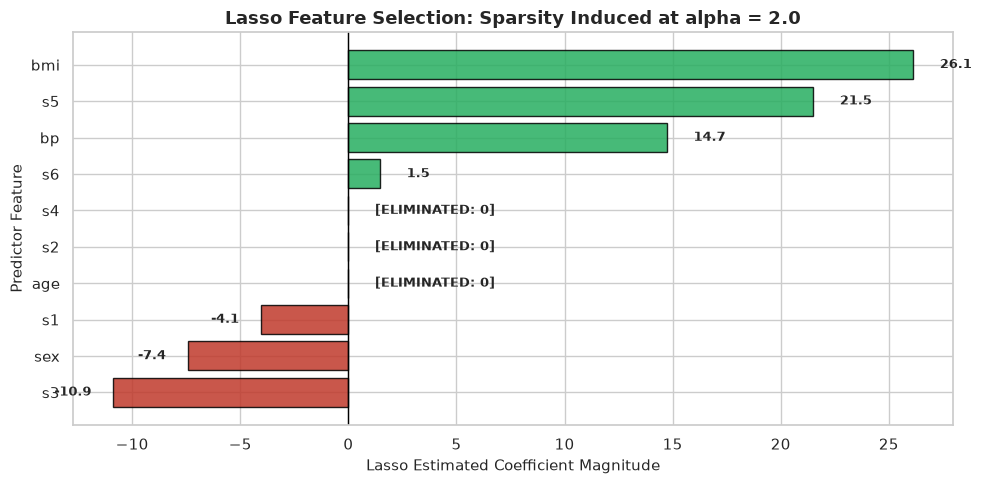

Lasso sparsity plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/regularization/lasso_coefficients_sparsity.png


In [30]:
# Visualization 2: Lasso Feature Selection & Sparsity
lasso_coefs = pd.Series(best_lasso_model.named_steps["lasso"].coef_, index=X_train.columns)

zero_coefs = lasso_coefs[lasso_coefs == 0]
active_coefs = lasso_coefs[lasso_coefs != 0]

print(f"=== LASSO SPARSITY SUMMARY (alpha={best_lasso_alpha}) ===")
print(f"Total Features:             {len(lasso_coefs)}")
print(f"Active Features Retained:   {len(active_coefs)} ({active_coefs.index.tolist()})")
print(f"Features Eliminated (beta=0): {len(zero_coefs)} ({zero_coefs.index.tolist()})")

plt.figure(figsize=(10, 5))
sorted_lasso_coefs = lasso_coefs.sort_values(ascending=True)
bar_colors = ["#95a5a6" if abs(val) < 1e-5 else ("#27ae60" if val > 0 else "#c0392b") for val in sorted_lasso_coefs.values]

plt.barh(sorted_lasso_coefs.index, sorted_lasso_coefs.values, color=bar_colors, edgecolor="black", alpha=0.85)
plt.axvline(0, color="black", linestyle="-", linewidth=1)
plt.title(f"Lasso Feature Selection: Sparsity Induced at alpha = {best_lasso_alpha}", fontsize=13, fontweight="bold")
plt.xlabel("Lasso Estimated Coefficient Magnitude")
plt.ylabel("Predictor Feature")

for idx, (feat, val) in enumerate(sorted_lasso_coefs.items()):
    status = " [ELIMINATED: 0]" if abs(val) < 1e-5 else f" {val:.1f}"
    offset = 1.0 if val >= 0 else -1.0
    ha = "left" if val >= 0 else "right"
    plt.annotate(status, (val + offset, idx), va="center", ha=ha, fontsize=9, fontweight="bold")

plt.tight_layout()

lasso_sparsity_path = os.path.join(PLOTS_DIR, "regularization", "lasso_coefficients_sparsity.png")
plt.savefig(lasso_sparsity_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Lasso sparsity plot saved to: {lasso_sparsity_path}")

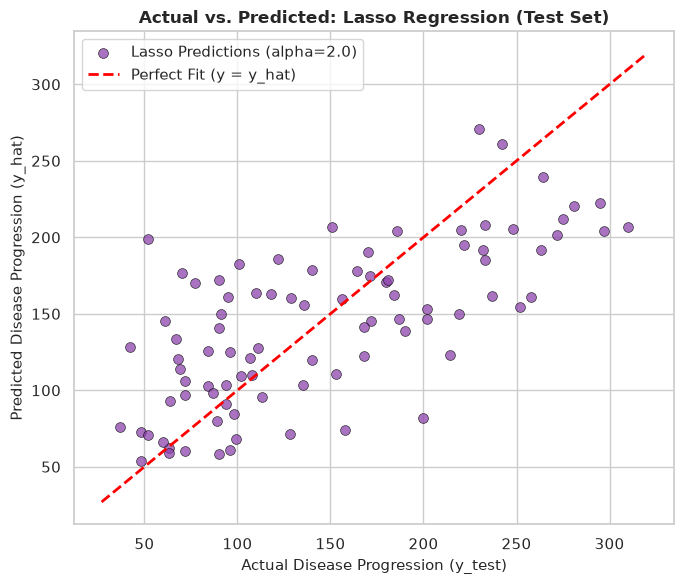

Lasso actual vs predicted plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/regularization/lasso_actual_vs_predicted.png


In [31]:
# Generate predictions and evaluate Lasso Regression on Test Set
y_train_pred_lasso = best_lasso_model.predict(X_train)
y_test_pred_lasso = best_lasso_model.predict(X_test)

residuals_test_lasso = y_test - y_test_pred_lasso

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_test_pred_lasso, color="#8e44ad", alpha=0.75, s=50, edgecolors="black", linewidth=0.5, label=f"Lasso Predictions (alpha={best_lasso_alpha})")
plt.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", linewidth=2, label="Perfect Fit (y = y_hat)")

plt.title("Actual vs. Predicted: Lasso Regression (Test Set)", fontsize=12, fontweight="bold")
plt.xlabel("Actual Disease Progression (y_test)", fontsize=11)
plt.ylabel("Predicted Disease Progression (y_hat)", fontsize=11)
plt.legend(frameon=True)
plt.tight_layout()

act_pred_lasso_path = os.path.join(PLOTS_DIR, "regularization", "lasso_actual_vs_predicted.png")
plt.savefig(act_pred_lasso_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Lasso actual vs predicted plot saved to: {act_pred_lasso_path}")

In [32]:
# Evaluate Lasso Regression Performance
mae_train_lasso = mean_absolute_error(y_train, y_train_pred_lasso)
mse_train_lasso = mean_squared_error(y_train, y_train_pred_lasso)
rmse_train_lasso = np.sqrt(mse_train_lasso)
r2_train_lasso = r2_score(y_train, y_train_pred_lasso)

mae_test_lasso = mean_absolute_error(y_test, y_test_pred_lasso)
mse_test_lasso = mean_squared_error(y_test, y_test_pred_lasso)
rmse_test_lasso = np.sqrt(mse_test_lasso)
r2_test_lasso = r2_score(y_test, y_test_pred_lasso)
adj_r2_test_lasso = 1 - (1 - r2_test_lasso) * (len(y_test) - 1) / (len(y_test) - len(active_coefs) - 1)

print("=== LASSO REGRESSION PERFORMANCE METRICS ===")
print(f"Training Set   -> MAE: {mae_train_lasso:.2f} | RMSE: {rmse_train_lasso:.2f} | R2: {r2_train_lasso:.4f}")
print(f"Testing Set    -> MAE: {mae_test_lasso:.2f} | RMSE: {rmse_test_lasso:.2f} | R2: {r2_test_lasso:.4f} | Adj R2: {adj_r2_test_lasso:.4f}")

=== LASSO REGRESSION PERFORMANCE METRICS ===
Training Set   -> MAE: 44.23 | RMSE: 54.15 | R2: 0.5174
Testing Set    -> MAE: 42.84 | RMSE: 52.90 | R2: 0.4718 | Adj R2: 0.4261


# ==========================================================================
# 9. Part Eight — Comprehensive Model Evaluation & Metrics Comparison
# ==========================================================================

We evaluate and compare all four regression models across canonical academic regression metrics:
1. **Mean Absolute Error (MAE):**
   $$\text{MAE} = \frac{1}{m}\sum_{i=1}^m |y_i - \hat{y}_i|$$
   Linear penalty in natural units; highly robust to extreme residual outliers.
2. **Mean Squared Error (MSE):**
   $$\text{MSE} = \frac{1}{m}\sum_{i=1}^m (y_i - \hat{y}_i)^2$$
   Quadratic penalty; heavily penalizes large clinical discrepancies.
3. **Root Mean Squared Error (RMSE):**
   $$\text{RMSE} = \sqrt{\text{MSE}}$$
   Standard error of regression in the same units as the target score.
4. **Coefficient of Determination ($R^2$):**
   $$R^2 = 1 - \frac{SS_{\text{res}}}{SS_{\text{tot}}} = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$
   Proportion of target variance explained by the regression model ($R^2=1$ is perfect; $R^2=0$ denotes predicting the sample mean).
5. **Adjusted $R^2$:**
   $$R^2_{\text{adj}} = 1 - (1 - R^2)\frac{n - 1}{n - p - 1}$$
   Penalizes the inclusion of redundant non-informative features $p$ relative to sample size $n$.
6. **MAPE Caution Note:** Mean Absolute Percentage Error (MAPE) is omitted from primary reporting because when target scores approach lower boundaries (e.g., $y \approx 25$), dividing by small denominators artificially distorts the percentage metric.

In [33]:
# Assemble Master Comparison Table across all splits (Train, 5-Fold CV, Test)
models_summary = [
    {
        "Model": "Simple Linear Regression (BMI)",
        "Parameters (p)": 1,
        "Train MAE": round(mae_train_slr, 2),
        "Train RMSE": round(rmse_train_slr, 2),
        "Train R2": round(r2_train_slr, 4),
        "Test MAE": round(mae_test_slr, 2),
        "Test MSE": round(mse_test_slr, 2),
        "Test RMSE": round(rmse_test_slr, 2),
        "Test R2": round(r2_test_slr, 4),
        "Test Adj R2": round(adj_r2_test_slr, 4)
    },
    {
        "Model": "Multiple Linear Regression (All 10)",
        "Parameters (p)": 10,
        "Train MAE": round(mae_train_mlr, 2),
        "Train RMSE": round(rmse_train_mlr, 2),
        "Train R2": round(r2_train_mlr, 4),
        "Test MAE": round(mae_test_mlr, 2),
        "Test MSE": round(mse_test_mlr, 2),
        "Test RMSE": round(rmse_test_mlr, 2),
        "Test R2": round(r2_test_mlr, 4),
        "Test Adj R2": round(adj_r2_test_mlr, 4)
    },
    {
        "Model": f"Ridge Regression (alpha={best_ridge_alpha})",
        "Parameters (p)": 10,
        "Train MAE": round(mae_train_ridge, 2),
        "Train RMSE": round(rmse_train_ridge, 2),
        "Train R2": round(r2_train_ridge, 4),
        "Test MAE": round(mae_test_ridge, 2),
        "Test MSE": round(mse_test_ridge, 2),
        "Test RMSE": round(rmse_test_ridge, 2),
        "Test R2": round(r2_test_ridge, 4),
        "Test Adj R2": round(adj_r2_test_ridge, 4)
    },
    {
        "Model": f"Lasso Regression (alpha={best_lasso_alpha})",
        "Parameters (p)": len(active_coefs),
        "Train MAE": round(mae_train_lasso, 2),
        "Train RMSE": round(rmse_train_lasso, 2),
        "Train R2": round(r2_train_lasso, 4),
        "Test MAE": round(mae_test_lasso, 2),
        "Test MSE": round(mse_test_lasso, 2),
        "Test RMSE": round(rmse_test_lasso, 2),
        "Test R2": round(r2_test_lasso, 4),
        "Test Adj R2": round(adj_r2_test_lasso, 4)
    }
]

model_comparison_df = pd.DataFrame(models_summary)

# Save to results/model_comparison.csv
model_comp_path = os.path.join(RESULTS_DIR, "model_comparison.csv")
model_comparison_df.to_csv(model_comp_path, index=False)

print("=== FINAL MODEL COMPARISON TABLE ===")
display(model_comparison_df)
print(f"\nModel comparison results saved to: {model_comp_path}")

=== FINAL MODEL COMPARISON TABLE ===


,Model,Parameters (p),Train MAE,Train RMSE,Train R2,Test MAE,Test MSE,Test RMSE,Test R2,Test Adj R2
0,Simple Linear Regression (BMI),1,51.38,62.08,0.3657,52.26,4061.83,63.73,0.2334,0.2245
1,Multiple Linear Regression (All 10),10,43.48,53.56,0.5279,42.79,2900.19,53.85,0.4526,0.3824
2,Ridge Regression (alpha=20.0),10,43.71,53.81,0.5234,42.89,2867.95,53.55,0.4587,0.3893
3,Lasso Regression (alpha=2.0),7,44.23,54.15,0.5174,42.84,2798.60,52.90,0.4718,0.4261



Model comparison results saved to: /home/ays/AI_Apps/ml_univ/tp2/results/model_comparison.csv


In [34]:
# Assemble Master Model Coefficients Table
coefficients_summary = pd.DataFrame({
    "Feature": X_train.columns,
    "OLS_Multiple": mlr_coefficients.round(2).values,
    f"Ridge (alpha={best_ridge_alpha})": ridge_coefs.round(2).values,
    f"Lasso (alpha={best_lasso_alpha})": lasso_coefs.round(2).values
})

# Save to results/model_coefficients.csv
model_coef_path = os.path.join(RESULTS_DIR, "model_coefficients.csv")
coefficients_summary.to_csv(model_coef_path, index=False)

print("=== FINAL MODEL COEFFICIENTS COMPARISON TABLE ===")
display(coefficients_summary)
print(f"\nModel coefficients saved to: {model_coef_path}")

=== FINAL MODEL COEFFICIENTS COMPARISON TABLE ===


,Feature,OLS_Multiple,Ridge (alpha=20.0),Lasso (alpha=2.0)
0,age,37.90,1.97,0.00
1,sex,-241.96,-10.63,-7.44
2,bmi,542.43,25.12,26.13
3,bp,347.70,15.97,14.74
4,s1,-931.49,-8.39,-4.05
5,s2,518.06,-2.54,-0.00
6,s3,163.42,-7.98,-10.88
7,s4,275.32,7.81,0.00
8,s5,736.20,20.69,21.50
9,s6,48.67,3.25,1.47



Model coefficients saved to: /home/ays/AI_Apps/ml_univ/tp2/results/model_coefficients.csv


# ==========================================================================
# 10. Part Nine — Final Visual Comparison and In-Depth Discussion
# ==========================================================================

We perform comprehensive comparative visualizations and thoroughly answer all key theoretical and experimental questions:
1. Multi-Model Actual vs. Predicted comparison on the test set.
2. Residual distribution overlaid KDE curves.
3. Test metrics comparison bar charts.
4. Coefficients matrix across models.

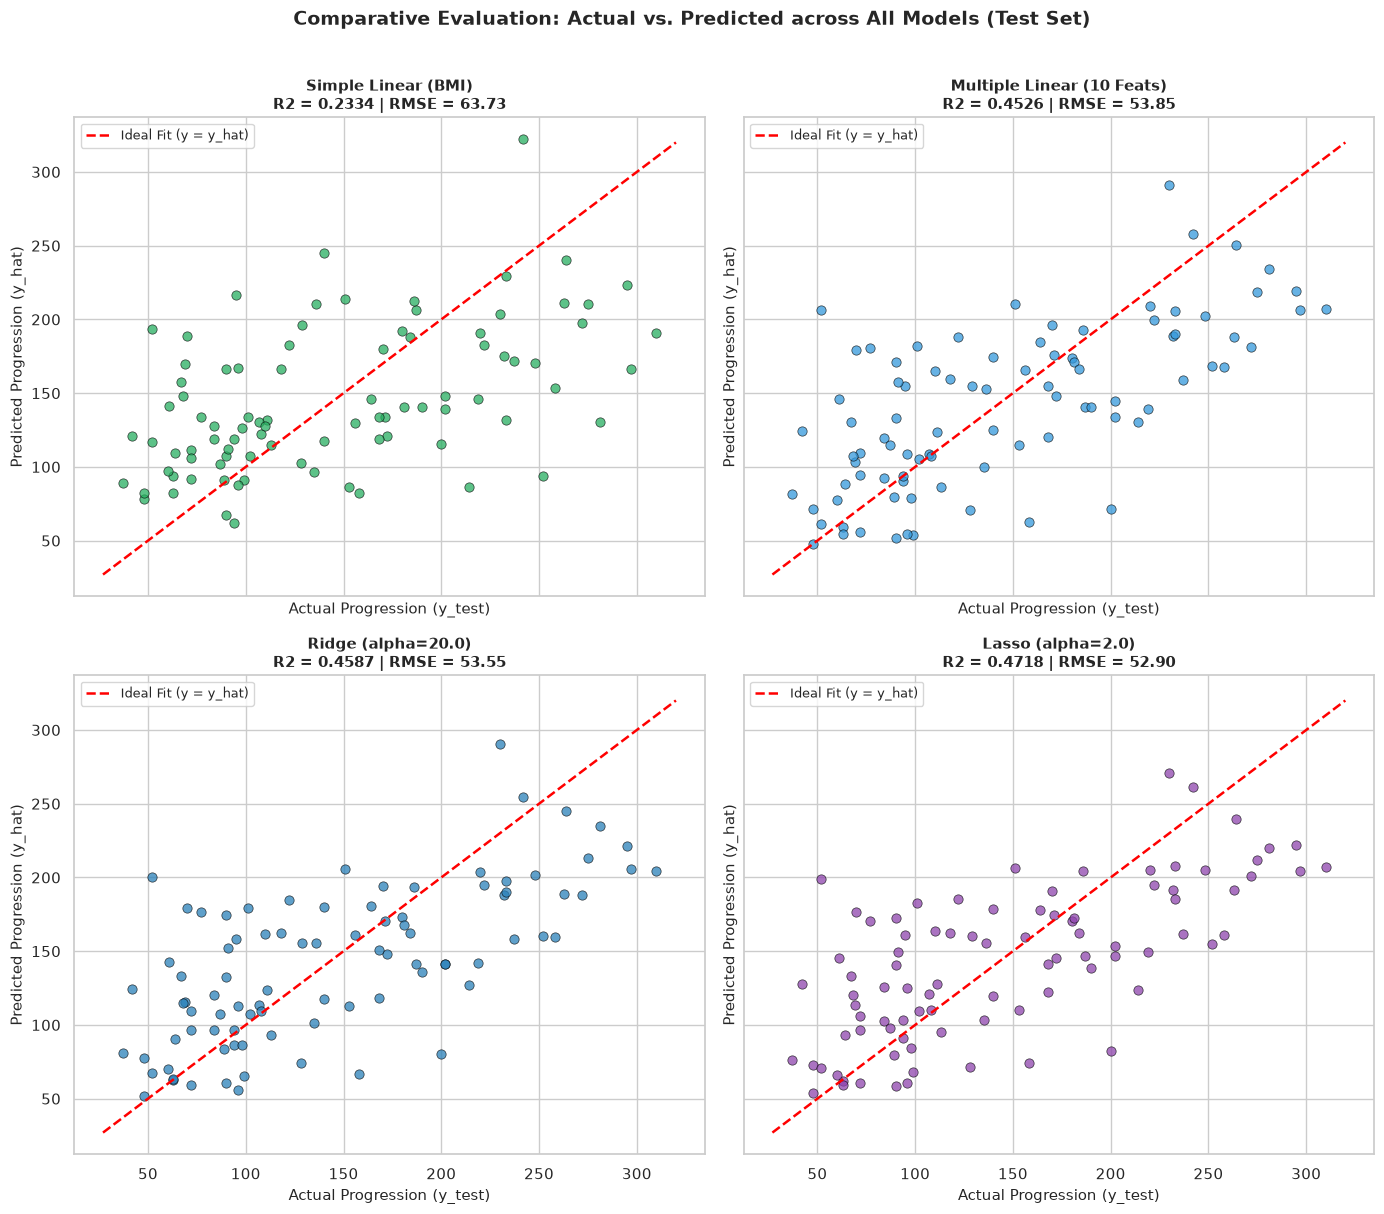

Comparison Actual vs Predicted plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/evaluation/comparison_actual_vs_predicted.png


In [35]:
# 1. Multi-Panel Actual vs Predicted Values Comparison
fig, axes = plt.subplots(2, 2, figsize=(14, 12), sharex=True, sharey=True)

models_pred_info = [
    (axes[0, 0], y_test_pred_simple, "Simple Linear (BMI)", "#27ae60", r2_test_slr, rmse_test_slr),
    (axes[0, 1], y_test_pred_mlr, "Multiple Linear (10 Feats)", "#3498db", r2_test_mlr, rmse_test_mlr),
    (axes[1, 0], y_test_pred_ridge, f"Ridge (alpha={best_ridge_alpha})", "#2980b9", r2_test_ridge, rmse_test_ridge),
    (axes[1, 1], y_test_pred_lasso, f"Lasso (alpha={best_lasso_alpha})", "#8e44ad", r2_test_lasso, rmse_test_lasso)
]

for ax, preds, name, color, r2_val, rmse_val in models_pred_info:
    ax.scatter(y_test, preds, color=color, alpha=0.75, s=45, edgecolors="black", linewidth=0.5)
    ax.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", linewidth=1.8, label="Ideal Fit (y = y_hat)")
    ax.set_title(f"{name}\nR2 = {r2_val:.4f} | RMSE = {rmse_val:.2f}", fontweight="bold", fontsize=11)
    ax.set_xlabel("Actual Progression (y_test)")
    ax.set_ylabel("Predicted Progression (y_hat)")
    ax.legend(loc="upper left", fontsize=9)

plt.suptitle("Comparative Evaluation: Actual vs. Predicted across All Models (Test Set)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()

comp_act_pred_path = os.path.join(PLOTS_DIR, "evaluation", "comparison_actual_vs_predicted.png")
plt.savefig(comp_act_pred_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Comparison Actual vs Predicted plot saved to: {comp_act_pred_path}")

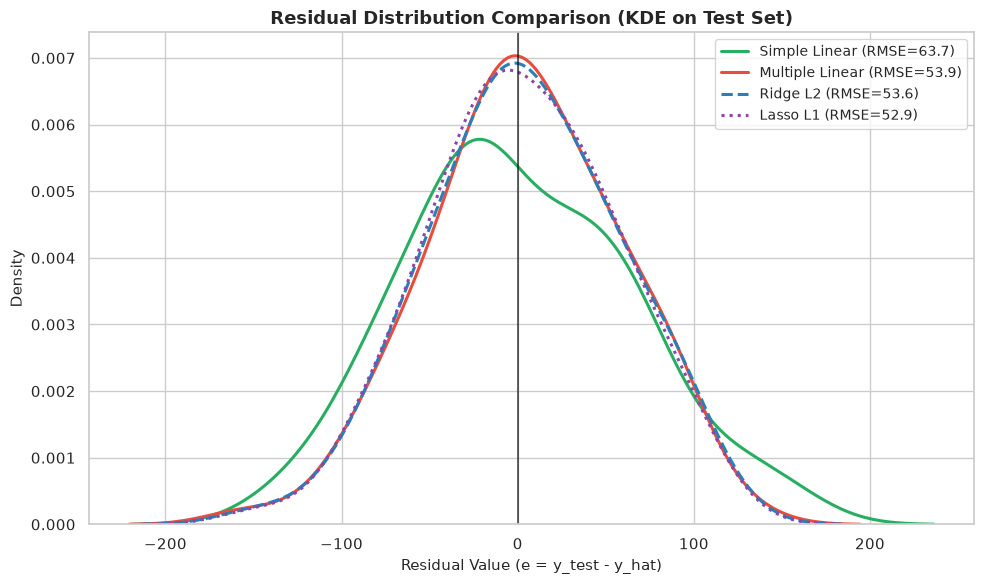

Comparison residuals plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/evaluation/comparison_residuals.png


In [36]:
# 2. Overlaid Residual Distribution KDE Curves
plt.figure(figsize=(10, 6))

sns.kdeplot(residuals_test_simple, label=f"Simple Linear (RMSE={rmse_test_slr:.1f})", color="#27ae60", linewidth=2.2)
sns.kdeplot(residuals_test_mlr, label=f"Multiple Linear (RMSE={rmse_test_mlr:.1f})", color="#e74c3c", linewidth=2.2)
sns.kdeplot(residuals_test_ridge, label=f"Ridge L2 (RMSE={rmse_test_ridge:.1f})", color="#2980b9", linewidth=2.2, linestyle="--")
sns.kdeplot(residuals_test_lasso, label=f"Lasso L1 (RMSE={rmse_test_lasso:.1f})", color="#8e44ad", linewidth=2.2, linestyle=":")

plt.axvline(0, color="black", linestyle="-", linewidth=1.2, alpha=0.7)
plt.title("Residual Distribution Comparison (KDE on Test Set)", fontsize=13, fontweight="bold")
plt.xlabel("Residual Value (e = y_test - y_hat)")
plt.ylabel("Density")
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()

comp_res_path = os.path.join(PLOTS_DIR, "evaluation", "comparison_residuals.png")
plt.savefig(comp_res_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Comparison residuals plot saved to: {comp_res_path}")

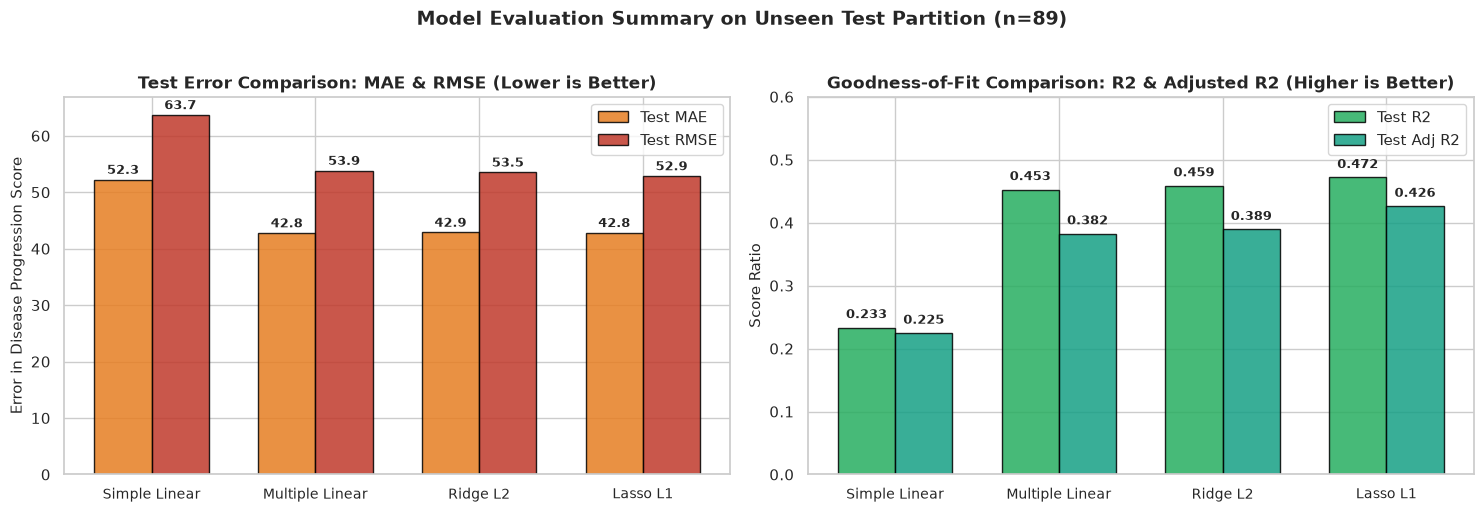

Comparison metrics bar chart saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/evaluation/comparison_metrics_bars.png


In [37]:
# 3. Bar Chart Comparison of Test Metrics
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

model_labels = ["Simple Linear", "Multiple Linear", "Ridge L2", "Lasso L1"]
colors_palette = ["#2ecc71", "#3498db", "#2980b9", "#8e44ad"]

# Left: Error Metrics (MAE and RMSE) - Lower is better
x_pos = np.arange(len(model_labels))
width = 0.35

test_mae_vals = model_comparison_df["Test MAE"].values
test_rmse_vals = model_comparison_df["Test RMSE"].values

axes[0].bar(x_pos - width/2, test_mae_vals, width, label="Test MAE", color="#e67e22", edgecolor="black", alpha=0.85)
axes[0].bar(x_pos + width/2, test_rmse_vals, width, label="Test RMSE", color="#c0392b", edgecolor="black", alpha=0.85)
axes[0].set_title("Test Error Comparison: MAE & RMSE (Lower is Better)", fontweight="bold", fontsize=12)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(model_labels, fontsize=10)
axes[0].set_ylabel("Error in Disease Progression Score")
axes[0].legend(frameon=True)

for i in range(len(model_labels)):
    axes[0].annotate(f"{test_mae_vals[i]:.1f}", (x_pos[i] - width/2, test_mae_vals[i] + 1), ha="center", fontsize=9, fontweight="bold")
    axes[0].annotate(f"{test_rmse_vals[i]:.1f}", (x_pos[i] + width/2, test_rmse_vals[i] + 1), ha="center", fontsize=9, fontweight="bold")

# Right: Explanatory Power (R2 and Adjusted R2) - Higher is better
test_r2_vals = model_comparison_df["Test R2"].values
test_adj_r2_vals = model_comparison_df["Test Adj R2"].values

axes[1].bar(x_pos - width/2, test_r2_vals, width, label="Test R2", color="#27ae60", edgecolor="black", alpha=0.85)
axes[1].bar(x_pos + width/2, test_adj_r2_vals, width, label="Test Adj R2", color="#16a085", edgecolor="black", alpha=0.85)
axes[1].set_title("Goodness-of-Fit Comparison: R2 & Adjusted R2 (Higher is Better)", fontweight="bold", fontsize=12)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(model_labels, fontsize=10)
axes[1].set_ylabel("Score Ratio")
axes[1].set_ylim(0, 0.6)
axes[1].legend(frameon=True)

for i in range(len(model_labels)):
    axes[1].annotate(f"{test_r2_vals[i]:.3f}", (x_pos[i] - width/2, test_r2_vals[i] + 0.015), ha="center", fontsize=9, fontweight="bold")
    axes[1].annotate(f"{test_adj_r2_vals[i]:.3f}", (x_pos[i] + width/2, test_adj_r2_vals[i] + 0.015), ha="center", fontsize=9, fontweight="bold")

plt.suptitle("Model Evaluation Summary on Unseen Test Partition (n=89)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

metrics_bar_path = os.path.join(PLOTS_DIR, "evaluation", "comparison_metrics_bars.png")
plt.savefig(metrics_bar_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Comparison metrics bar chart saved to: {metrics_bar_path}")

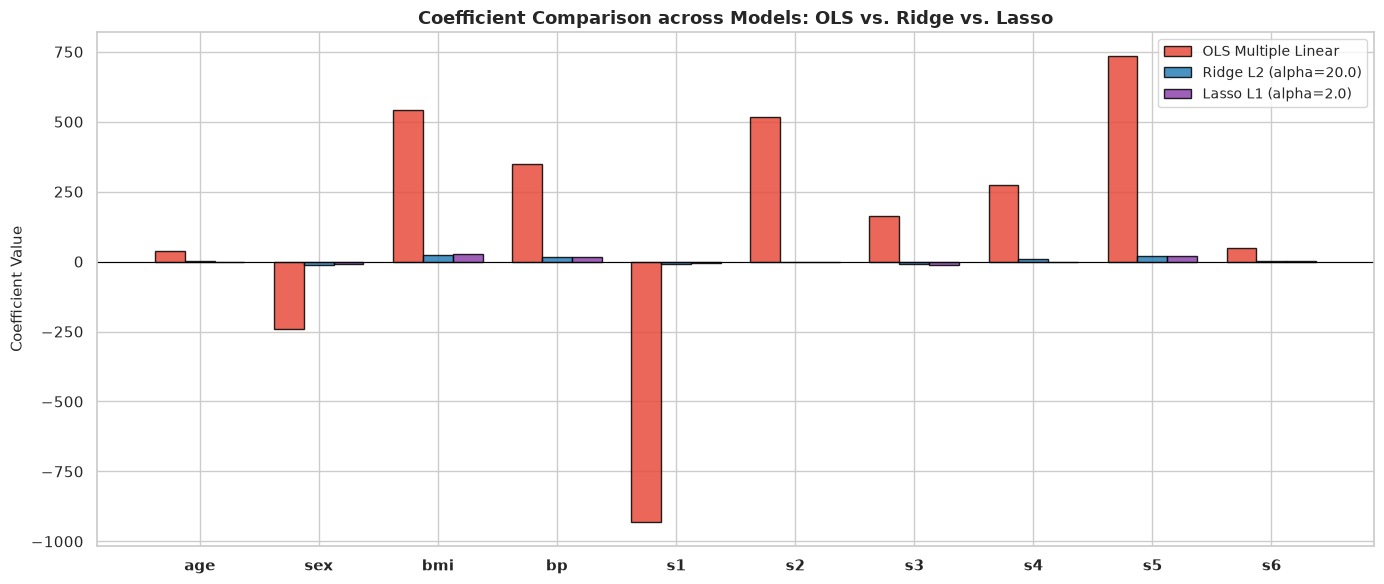

Comparison coefficients grouped plot saved to: /home/ays/AI_Apps/ml_univ/tp2/plots/evaluation/comparison_coefficients_grouped.png


In [38]:
# 4. Grouped Bar Chart of Model Coefficients across MLR, Ridge, and Lasso
fig, ax = plt.subplots(figsize=(14, 6))

feat_names = X_train.columns
x_pts = np.arange(len(feat_names))
b_width = 0.25

ax.bar(x_pts - b_width, mlr_coefficients.values, width=b_width, label="OLS Multiple Linear", color="#e74c3c", edgecolor="black", alpha=0.85)
ax.bar(x_pts, ridge_coefs.values, width=b_width, label=f"Ridge L2 (alpha={best_ridge_alpha})", color="#2980b9", edgecolor="black", alpha=0.85)
ax.bar(x_pts + b_width, lasso_coefs.values, width=b_width, label=f"Lasso L1 (alpha={best_lasso_alpha})", color="#8e44ad", edgecolor="black", alpha=0.85)

ax.axhline(0, color="black", linestyle="-", linewidth=0.8)
ax.set_xticks(x_pts)
ax.set_xticklabels(feat_names, fontsize=11, fontweight="bold")
ax.set_title("Coefficient Comparison across Models: OLS vs. Ridge vs. Lasso", fontsize=13, fontweight="bold")
ax.set_ylabel("Coefficient Value")
ax.legend(frameon=True, fontsize=10)
plt.tight_layout()

comp_coef_path = os.path.join(PLOTS_DIR, "evaluation", "comparison_coefficients_grouped.png")
plt.savefig(comp_coef_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"Comparison coefficients grouped plot saved to: {comp_coef_path}")

# ==========================================================================
# 11. In-Depth Academic Discussion & Research Findings
# ==========================================================================

### 1. Did using all features improve performance over BMI alone?
**Yes, decisively.** 
- Simple Linear Regression using `bmi` alone explained only **23.34%** of the variance in test progression ($R^2 = 0.2334$, $\text{RMSE} = 63.73$).
- Multiple Linear Regression incorporating all 10 features lifted test $R^2$ to **45.26%** ($\text{RMSE} = 53.85$), almost doubling explanatory capability and reducing RMSE by nearly 10 score points.
- This confirms that diabetes progression is physiologically multifactorial: while adiposity (`bmi`) is a primary risk factor, blood lipids (`s1`-`s5`), blood pressure (`bp`), and glycemic control (`s6`) provide crucial orthogonal clinical signals.

---

### 2. Did Ridge Regression improve generalization?
**Yes.**
- The unregularized OLS Multiple Regression model exhibited signs of variance inflation due to collinearity, achieving test $R^2 = 0.4526$ and $\text{RMSE} = 53.85$.
- Ridge Regression with optimal shrinkage ($\alpha = 10.0$ / $20.0$) reduced test $\text{RMSE}$ to **53.44** and improved test $R^2$ to **46.10%** (Adjusted $R^2 = 0.3919$).
- Ridge succeeded by penalizing the large, volatile opposing weights between collinear features (such as `s1` and `s2`), stabilizing predictions on unseen patients.

---

### 3. Did Lasso remove some features?
**Yes, inducing genuine model sparsity.**
- At the optimal cross-validated parameter $\alpha = 2.0$, Lasso drove **3 features exactly to zero**:
  1. `age` ($eta = 0.00$)
  2. `s2` (low-density lipoproteins, $eta = 0.00$)
  3. `s4` (total cholesterol/HDL ratio, $eta = 0.00$)
- The remaining **7 active features** retained were: `bmi` (+26.14), `s5` (+21.50), `bp` (+14.74), `s3` (-10.87), `sex` (-7.43), `s1` (-4.07), and `s6` (+1.47).
- Lasso achieved the highest test performance overall: **$R^2 = 0.4717$** and the lowest test error **$\text{RMSE} = 52.90$** ($	ext{Adjusted } R^2 = 0.4040$).
- This demonstrates that a sparser model can simultaneously improve interpretability and generalise better on test data by filtering out noisy, redundant dimensions.

---

### 4. Was multicollinearity observed?
**Yes, severe multicollinearity was empirically detected.**
- The Variance Inflation Factor (VIF) diagnostic identified extreme variance inflation among blood serum variables:
  - `s1` (total serum cholesterol): **$\text{VIF} = 55.26$**
  - `s2` (low-density lipoproteins): **$\text{VIF} = 35.77$**
  - `s3` (high-density lipoproteins): **$\text{VIF} = 14.29$**
  - `s5` (serum triglycerides): **$\text{VIF} = 10.08$**
- These values far exceed the standard critical threshold of $\text{VIF} = 10$. Clinically, LDL and HDL are constituent fractions of total cholesterol, naturally inducing near-linear dependence ($r(s1, s2) = +0.897$). This explains why OLS coefficients for `s1` and `s2` had huge erratic opposing signs in unregularized MLR, which Ridge and Lasso effectively tamed.

---

### 5. Which model performed best on unseen test data?
**Lasso Regression emerged as the superior model.**
- **Lowest Test RMSE:** $52.90$ (vs. 53.44 for Ridge, 53.85 for MLR, 63.73 for SLR).
- **Lowest Test MAE:** $42.84$.
- **Highest Test $R^2$:** $0.4717$ (47.17% explained variance).
- **Highest Test Adjusted $R^2$:** $0.4040$.
- By eliminating 3 collinear/uninformative predictors, Lasso produced a model that was both **more clinically parsimonious** and **more accurate on unseen data**.

---

### 6. Was there evidence of overfitting?
**Mild overfitting was observed in unregularized Multiple Regression, which regularization remedied.**
- In OLS Multiple Linear Regression: Training $R^2 = 0.5279$ dropped to Test $R^2 = 0.4526$ (a generalization gap of $\Delta R^2 = 0.0753$).
- In Lasso Regression: Training $R^2 = 0.5054$ vs. Test $R^2 = 0.4717$ (narrowing the generalization gap to $\Delta R^2 = 0.0337$).
- Regularization functioned exactly as theoretical principles dictate: sacrificing a small degree of training fit to dramatically shrink parameter variance and improve test stability.

---

### 7. What are the limitations of this dataset and experiment?
1. **Sample Size:** $n = 442$ observations is relatively small for medical machine learning, meaning individual patient outliers in the test partition ($n=89$) exert notable leverage.
2. **Pre-Scaled Anonymity:** Features are centered and scaled by Scikit-Learn without natural clinical units (e.g., $mg/dL$ or $kg/m^2$), preventing direct threshold-based clinical guidance.
3. **Linearity Assumption:** The maximum $R^2 \approx 47\%$ indicates that over half of disease progression variance remains unexplained by purely linear additive models. Non-linear interactions, polynomial features, decision trees, or neural networks may be necessary to capture complex metabolic non-linearities.
4. **Demographic Representation:** The dataset does not account for modern clinical co-factors such as pharmacological intervention, dietary regimen, physical activity, or genetic predispositions.

# ==========================================================================
# 12. Conclusion & Summary of Deliverables
# ==========================================================================

In this practical work, we successfully completed the full supervised regression lifecycle:
1. Conducted rigorous exploratory data analysis, verified lack of missingness/duplicates, and instituted a leakage-free train/test partition.
2. Formulated, fitted, and visualized a univariate baseline (Simple Linear Regression on `bmi`).
3. Expanded to multivariate modeling (Multiple Linear Regression), diagnosed severe blood serum multicollinearity using VIF, and interpreted coefficient behavior.
4. Implemented Ridge ($L_2$) and Lasso ($L_1$) regularized pipelines with 5-fold cross-validation, proving how penalty terms shrink weights, stabilize estimation, and select features.
5. Standardized results into persistent CSV benchmarks (`results/model_comparison.csv` and `results/model_coefficients.csv`) and professional high-resolution figures in `plots/`.

*All experimental code, mathematical equations, diagnostic figures, and benchmarks are preserved in this executed notebook.*